In [1]:
from pyspark.sql import SparkSession
import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("WeatherIntelligence")
    .master("local[*]")
    .getOrCreate()
)

print("Spark Version:", spark.version)
print("Spark Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)

Spark Version: 4.2.0
Spark Application: WeatherIntelligence
Master: local[*]


In [2]:

project_dir = os.path.dirname(os.getcwd())
data_dir = os.path.join(project_dir, "Data")
raw_dir = os.path.join(data_dir, "raw")

print("Raw Data Directory:", raw_dir)
print("\nFiles:")
print(os.listdir(raw_dir))

Raw Data Directory: c:\Users\pavan\OneDrive\Desktop\DA_Assignments\Weather_Intelligence\Data\raw

Files:
['stations.csv', 'weather_alerts.csv', 'weather_forecasts.csv', 'weather_observations.csv']


In [3]:
#Dataset Inspection
datasets = {
    "stations": os.path.join(raw_dir, "stations.csv"),
    "observations": os.path.join(raw_dir, "weather_observations.csv"),
    "forecasts": os.path.join(raw_dir, "weather_forecasts.csv"),
    "alerts": os.path.join(raw_dir, "weather_alerts.csv")
}

for name, path in datasets.items():

    print(f"\n{'=' * 70}")
    print(f"DATASET: {name.upper()}")
    print(f"{'=' * 70}")

    # Read CSV using Spark for initial inspection
    df = (
        spark.read
        .option("header", True)
        .option("inferSchema", False)
        .csv(path)
    )

    print("\nSchema:")
    df.printSchema()

    print(f"\nTotal Rows: {df.count()}")
    print(f"Total Columns: {len(df.columns)}")

    print("\nColumn Names:")
    print(df.columns)

    print("\nFirst 5 Records:")
    df.show(5, truncate=False)


DATASET: STATIONS

Schema:
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- state: string (nullable = true)
 |-- elevation_m: string (nullable = true)


Total Rows: 8
Total Columns: 4

Column Names:
['station_id', 'station_name', 'state', 'elevation_m']

First 5 Records:
+----------+-------------+--------------+-----------+
|station_id|station_name |state         |elevation_m|
+----------+-------------+--------------+-----------+
|WX01      |Hyderabad    |Telangana     |300        |
|WX02      |Warangal     |Telangana     |700        |
|WX03      |Vijayawada   |Andhra Pradesh|700        |
|WX04      |Visakhapatnam|Andhra Pradesh|300        |
|WX05      |Pune         |Maharashtra   |300        |
+----------+-------------+--------------+-----------+
only showing top 5 rows

DATASET: OBSERVATIONS

Schema:
root
 |-- observation_id: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- observed_at: string (nullable = true)
 |

In [4]:
#Schema Definition and Data Ingestion
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    IntegerType,
    DoubleType,
    TimestampType
)

# 1. Define schemas

stations_schema = StructType([
    StructField("station_id", StringType(), True),
    StructField("station_name", StringType(), True),
    StructField("state", StringType(), True),
    StructField("elevation_m", IntegerType(), True)
])

observations_schema = StructType([
    StructField("observation_id", StringType(), True),
    StructField("station_id", StringType(), True),
    StructField("observed_at", TimestampType(), True),
    StructField("temperature_c", DoubleType(), True),
    StructField("humidity_pct", DoubleType(), True),
    StructField("rainfall_mm", DoubleType(), True),
    StructField("wind_kph", DoubleType(), True),
    StructField("condition", StringType(), True)
])

forecasts_schema = StructType([
    StructField("forecast_id", StringType(), True),
    StructField("station_id", StringType(), True),
    StructField("forecast_for", TimestampType(), True),
    StructField("forecast_temp_c", DoubleType(), True),
    StructField("forecast_rain_mm", DoubleType(), True),
    StructField("forecast_condition", StringType(), True)
])

alerts_schema = StructType([
    StructField("alert_id", StringType(), True),
    StructField("station_id", StringType(), True),
    StructField("alert_time", TimestampType(), True),
    StructField("alert_type", StringType(), True),
    StructField("severity", StringType(), True),
    StructField("status", StringType(), True)
])


# 2. Preserve raw datasets (all columns as strings)

raw_dfs = {
    name: (
        spark.read
        .option("header", True)
        .option("inferSchema", False)
        .csv(path)
    )
    for name, path in datasets.items()
}


# 3. Load datasets using explicit schemas

schemas = {
    "stations": stations_schema,
    "observations": observations_schema,
    "forecasts": forecasts_schema,
    "alerts": alerts_schema
}

dataframes = {
    name: (
        spark.read
        .option("header", True)
        .schema(schemas[name])
        .csv(datasets[name])
    )
    for name in datasets
}


# 4. Assign individual DataFrame variables

stations_df = dataframes["stations"]
observations_df = dataframes["observations"]
forecasts_df = dataframes["forecasts"]
alerts_df = dataframes["alerts"]


# 5. Verify loaded schemas

for name, df in dataframes.items():
    print(f"\n{'=' * 50}")
    print(f"{name.upper()} SCHEMA")
    print(f"{'=' * 50}")
    df.printSchema()


STATIONS SCHEMA
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- state: string (nullable = true)
 |-- elevation_m: integer (nullable = true)


OBSERVATIONS SCHEMA
root
 |-- observation_id: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- observed_at: timestamp (nullable = true)
 |-- temperature_c: double (nullable = true)
 |-- humidity_pct: double (nullable = true)
 |-- rainfall_mm: double (nullable = true)
 |-- wind_kph: double (nullable = true)
 |-- condition: string (nullable = true)


FORECASTS SCHEMA
root
 |-- forecast_id: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- forecast_for: timestamp (nullable = true)
 |-- forecast_temp_c: double (nullable = true)
 |-- forecast_rain_mm: double (nullable = true)
 |-- forecast_condition: string (nullable = true)


ALERTS SCHEMA
root
 |-- alert_id: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- alert_time: timestamp (nulla

## **Initial Data Quality Assessment**

In [5]:
#Finding Missing Values in each raw dataset
for name, df in raw_dfs.items():

    print(f"\n{'=' * 60}")
    print(f"MISSING VALUE PROFILE: {name.upper()}")
    print(f"{'=' * 60}")

    total_rows = df.count()

    for column in df.columns:

        missing_count = df.filter(
            F.col(column).isNull()
            | (F.trim(F.col(column)) == "")
        ).count()

        if missing_count > 0:
            percentage = (missing_count / total_rows) * 100

            print(
                f"{column}: {missing_count} missing "
                f"({percentage:.2f}%)"
            )


MISSING VALUE PROFILE: STATIONS

MISSING VALUE PROFILE: OBSERVATIONS
temperature_c: 9 missing (0.28%)
humidity_pct: 10 missing (0.31%)
rainfall_mm: 20 missing (0.62%)
wind_kph: 8 missing (0.25%)
condition: 492 missing (15.36%)

MISSING VALUE PROFILE: FORECASTS
forecast_temp_c: 3 missing (0.30%)
forecast_rain_mm: 3 missing (0.30%)
forecast_condition: 168 missing (16.80%)

MISSING VALUE PROFILE: ALERTS
severity: 29 missing (13.18%)


In [6]:
#duplicate keys checker function
def find_duplicate_keys(df, key_columns):
    return (
        df.groupBy(*key_columns)
        .count()
        .filter(F.col("count") > 1)
        .orderBy(F.desc("count"))
    )

In [7]:
# Check duplicate identifier values in each typed DataFrame

primary_keys = {
    "stations": ("stations_df", stations_df, "station_id"),
    "observations": ("observations_df", observations_df, "observation_id"),
    "forecasts": ("forecasts_df", forecasts_df, "forecast_id"),
    "alerts": ("alerts_df", alerts_df, "alert_id")
}

for name, (df_name, df, key) in primary_keys.items():

    print(f"\n{'=' * 60}")
    print(f"DUPLICATE KEY CHECK: {name.upper()}")
    print(f"{'=' * 60}")

    duplicate_keys = find_duplicate_keys(df, [key])
    duplicate_groups = duplicate_keys.count()

    print(f"Duplicate key groups: {duplicate_groups}")

    if duplicate_groups > 0:
        print("\nDuplicate identifiers:")
        duplicate_keys.show(20, truncate=False)


DUPLICATE KEY CHECK: STATIONS
Duplicate key groups: 0

DUPLICATE KEY CHECK: OBSERVATIONS
Duplicate key groups: 3

Duplicate identifiers:
+--------------+-----+
|observation_id|count|
+--------------+-----+
|OBS00026      |2    |
|OBS00101      |2    |
|OBS00011      |2    |
+--------------+-----+


DUPLICATE KEY CHECK: FORECASTS
Duplicate key groups: 0

DUPLICATE KEY CHECK: ALERTS
Duplicate key groups: 0


In [8]:
# Inspect all records associated with duplicate observation IDs

duplicate_observation_ids = (
    observations_df
    .groupBy("observation_id")
    .count()
    .filter(F.col("count") > 1)
    .select("observation_id")
)

duplicate_observations = (
    observations_df
    .join(duplicate_observation_ids, on="observation_id", how="inner")
    .orderBy("observation_id")
)

duplicate_observations.show(truncate=False)

+--------------+----------+-------------------+-------------+------------+-----------+--------+----------+
|observation_id|station_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition |
+--------------+----------+-------------------+-------------+------------+-----------+--------+----------+
|OBS00011      |WX07      |2026-06-18 04:00:00|38.8         |65.0        |40.0       |37.7    |heavy rain|
|OBS00011      |WX07      |2026-06-18 04:00:00|38.8         |65.0        |40.0       |37.7    |heavy rain|
|OBS00026      |WX01      |2026-06-15 21:00:00|39.6         |46.0        |54.9       |54.5    |cloudy    |
|OBS00026      |WX01      |2026-06-15 21:00:00|39.6         |46.0        |54.9       |54.5    |cloudy    |
|OBS00101      |WX06      |2026-06-14 05:00:00|24.0         |36.0        |9.9        |32.3    |Clear     |
|OBS00101      |WX06      |2026-06-14 05:00:00|24.0         |36.0        |9.9        |32.3    |Clear     |
+--------------+----------+----------

In [9]:
# Count exact duplicate rows across all columns

total_rows = observations_df.count()

distinct_rows = observations_df.distinct().count()

exact_duplicate_count = total_rows - distinct_rows

print("Total rows:", total_rows)
print("Distinct rows:", distinct_rows)
print("Exact duplicate rows:", exact_duplicate_count)

Total rows: 3203
Distinct rows: 3200
Exact duplicate rows: 3


In [10]:
# Inspect distinct categorical values and their frequencies

categorical_columns = {
    "stations": (stations_df, ["state"]),
    "observations": (observations_df, ["condition"]),
    "forecasts": (forecasts_df, ["forecast_condition"]),
    "alerts": (alerts_df, ["alert_type", "severity", "status"])
}

for dataset_name, (df, columns) in categorical_columns.items():

    print(f"\n{'=' * 60}")
    print(f"CATEGORICAL VALUE ASSESSMENT: {dataset_name.upper()}")
    print(f"{'=' * 60}")

    for column in columns:

        print(f"\nColumn: {column}")

        (
            df.groupBy(column)
            .count()
            .orderBy(F.desc("count"))
            .show(50, truncate=False)
        )


CATEGORICAL VALUE ASSESSMENT: STATIONS

Column: state
+--------------+-----+
|state         |count|
+--------------+-----+
|Andhra Pradesh|2    |
|Telangana     |2    |
|Maharashtra   |2    |
|Karnataka     |1    |
|Tamil Nadu    |1    |
+--------------+-----+


CATEGORICAL VALUE ASSESSMENT: OBSERVATIONS

Column: condition
+----------+-----+
|condition |count|
+----------+-----+
|NULL      |492  |
|Clear     |477  |
|cloudy    |467  |
|clear     |466  |
|heavy rain|436  |
|RAIN      |435  |
|rain      |430  |
+----------+-----+


CATEGORICAL VALUE ASSESSMENT: FORECASTS

Column: forecast_condition
+------------------+-----+
|forecast_condition|count|
+------------------+-----+
|rain              |184  |
|Sunny             |169  |
|NULL              |168  |
|cloudy            |165  |
|sunny             |158  |
|storm             |156  |
+------------------+-----+


CATEGORICAL VALUE ASSESSMENT: ALERTS

Column: alert_type
+----------+-----+
|alert_type|count|
+----------+-----+
|flood_ri

In [11]:
# Preliminary numeric range assessment
#These are broad screening limits for this synthetic assignment, not official thresholds for every weather station.

numeric_ranges = {
    "stations": (
        stations_df,
        {"elevation_m": (-500, 9000)}
    ),
    "observations": (
        observations_df,
        {
            "temperature_c": (-50, 60),
            "humidity_pct": (0, 100),
            "rainfall_mm": (0, 1000),
            "wind_kph": (0, 400)
        }
    ),
    "forecasts": (
        forecasts_df,
        {
            "forecast_temp_c": (-50, 60),
            "forecast_rain_mm": (0, 1000)
        }
    )
}

for dataset_name, (df, columns) in numeric_ranges.items():

    print(f"\n{'=' * 60}")
    print(f"NUMERIC RANGE ASSESSMENT: {dataset_name.upper()}")
    print(f"{'=' * 60}")

    for column, (minimum, maximum) in columns.items():

        invalid_records = df.filter(
            F.col(column).isNotNull()
            & (
                (F.col(column) < minimum)
                | (F.col(column) > maximum)
            )
        )

        print(f"\nColumn: {column}")
        print(f"Allowed range: {minimum} to {maximum}")
        print(f"Out-of-range records: {invalid_records.count()}")

        invalid_records.select(
            "station_id", column
        ).show(10, truncate=False)


NUMERIC RANGE ASSESSMENT: STATIONS

Column: elevation_m
Allowed range: -500 to 9000
Out-of-range records: 0
+----------+-----------+
|station_id|elevation_m|
+----------+-----------+
+----------+-----------+


NUMERIC RANGE ASSESSMENT: OBSERVATIONS

Column: temperature_c
Allowed range: -50 to 60
Out-of-range records: 1
+----------+-------------+
|station_id|temperature_c|
+----------+-------------+
|WX08      |88.0         |
+----------+-------------+


Column: humidity_pct
Allowed range: 0 to 100
Out-of-range records: 185
+----------+------------+
|station_id|humidity_pct|
+----------+------------+
|WX02      |103.0       |
|WX02      |105.0       |
|WX06      |105.0       |
|WX04      |-5.0        |
|WX03      |102.0       |
|WX05      |101.0       |
|WX05      |101.0       |
|WX04      |104.0       |
|WX05      |102.0       |
|WX07      |105.0       |
+----------+------------+
only showing top 10 rows

Column: rainfall_mm
Allowed range: 0 to 1000
Out-of-range records: 1
+----------

In [12]:
# Inspect complete records containing invalid numeric measurements

invalid_observations = observations_df.filter(
    (F.col("temperature_c").isNotNull() &
     ~F.col("temperature_c").between(-50, 60))
    |
    (F.col("humidity_pct").isNotNull() &
     ~F.col("humidity_pct").between(0, 100))
    |
    (F.col("rainfall_mm").isNotNull() &
     ~F.col("rainfall_mm").between(0, 1000))
)

print("Records with at least one invalid numeric measurement:",
      invalid_observations.count())

invalid_observations.orderBy("observation_id").show(
    30, truncate=False
)

Records with at least one invalid numeric measurement: 187
+--------------+----------+-------------------+-------------+------------+-----------+--------+----------+
|observation_id|station_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition |
+--------------+----------+-------------------+-------------+------------+-----------+--------+----------+
|OBS00024      |WX02      |2026-06-28 03:00:00|35.2         |103.0       |62.6       |1.4     |rain      |
|OBS00035      |WX02      |2026-06-27 08:00:00|25.5         |105.0       |12.5       |20.5    |RAIN      |
|OBS00061      |WX08      |2026-06-27 00:00:00|88.0         |51.0        |37.8       |8.8     |rain      |
|OBS00067      |WX06      |2026-06-21 01:00:00|33.9         |105.0       |42.7       |53.4    |rain      |
|OBS00071      |WX04      |2026-06-25 13:00:00|25.8         |-5.0        |31.6       |22.8    |clear     |
|OBS00083      |WX03      |2026-06-01 04:00:00|27.3         |102.0       |57.2       

In [13]:
# Inspect malformed timestamp values from raw DataFrames

timestamp_columns = {
    "observations": (raw_dfs["observations"], "observed_at"),
    "forecasts": (raw_dfs["forecasts"], "forecast_for"),
    "alerts": (raw_dfs["alerts"], "alert_time")
}

for dataset_name, (df, column) in timestamp_columns.items():

    invalid_condition = (
        F.col(column).isNotNull()
        & (F.trim(F.col(column)) != "")
        & F.expr(f"try_cast(`{column}` AS TIMESTAMP)").isNull()
    )

    invalid_records = df.filter(invalid_condition)

    print(f"\n{dataset_name.upper()}")
    print("Malformed timestamp records:", invalid_records.count())

    invalid_records.show(truncate=False)


OBSERVATIONS
Malformed timestamp records: 1
+--------------+----------+-----------+-------------+------------+-----------+--------+---------+
|observation_id|station_id|observed_at|temperature_c|humidity_pct|rainfall_mm|wind_kph|condition|
+--------------+----------+-----------+-------------+------------+-----------+--------+---------+
|OBS00045      |WX05      |yesterday  |37.2         |99          |20.1       |22.5    |clear    |
+--------------+----------+-----------+-------------+------------+-----------+--------+---------+


FORECASTS
Malformed timestamp records: 1
+-----------+----------+------------+---------------+----------------+------------------+
|forecast_id|station_id|forecast_for|forecast_temp_c|forecast_rain_mm|forecast_condition|
+-----------+----------+------------+---------------+----------------+------------------+
|FC00040    |WX03      |TBD         |24.1           |19.0            |storm             |
+-----------+----------+------------+---------------+---------

In [14]:
# Test: Timestamp parsing with malformed-value handling

test_timestamps = [
    ("valid_timestamp", "2026-06-15 10:30:00"),
    ("valid_date", "2026-06-15"),
    ("malformed_timestamp", "not-a-date"),
    ("empty_timestamp", ""),
    ("null_timestamp", None)
]

test_timestamp_df = spark.createDataFrame(
    test_timestamps,
    ["record_id", "raw_timestamp"]
)

test_timestamp_results = (
    test_timestamp_df
    .withColumn(
        "parsed_timestamp",
        F.try_to_timestamp(
            F.when(
                F.trim(F.col("raw_timestamp")) == "",
                None
            ).otherwise(F.col("raw_timestamp"))
        )
    )
)

results = {
    row["record_id"]: row["parsed_timestamp"]
    for row in test_timestamp_results.collect()
}

assert results["valid_timestamp"] is not None
assert results["valid_date"] is not None
assert results["malformed_timestamp"] is None
assert results["empty_timestamp"] is None
assert results["null_timestamp"] is None

print("PASS: Timestamp parsing")
print("Valid timestamps parsed successfully.")
print("Malformed, empty and NULL timestamps handled correctly.")

PASS: Timestamp parsing
Valid timestamps parsed successfully.
Malformed, empty and NULL timestamps handled correctly.


In [15]:
# Check referential integrity against the station master

child_datasets = {
    "observations": observations_df,
    "forecasts": forecasts_df,
    "alerts": alerts_df
}

valid_station_ids = stations_df.select("station_id").distinct()

for dataset_name, df in child_datasets.items():

    orphan_records = df.join(
        valid_station_ids,
        on="station_id",
        how="left_anti"
    )

    print(f"\n{'=' * 60}")
    print(f"REFERENTIAL INTEGRITY: {dataset_name.upper()}")
    print(f"{'=' * 60}")

    print("Orphan records:", orphan_records.count())

    if orphan_records.count() > 0:
        orphan_records.show(20, truncate=False)


REFERENTIAL INTEGRITY: OBSERVATIONS
Orphan records: 1
+----------+--------------+-------------------+-------------+------------+-----------+--------+---------+
|station_id|observation_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition|
+----------+--------------+-------------------+-------------+------------+-----------+--------+---------+
|WX99      |OBS00032      |2026-06-06 00:00:00|31.1         |96.0        |28.6       |38.3    |clear    |
+----------+--------------+-------------------+-------------+------------+-----------+--------+---------+


REFERENTIAL INTEGRITY: FORECASTS
Orphan records: 1
+----------+-----------+-------------------+---------------+----------------+------------------+
|station_id|forecast_id|forecast_for       |forecast_temp_c|forecast_rain_mm|forecast_condition|
+----------+-----------+-------------------+---------------+----------------+------------------+
|WX77      |FC00019    |2026-06-04 21:00:00|38.8           |9.1        

## **Standardization and Transformation**

In [16]:

# Standardize categorical columns

observations_cleaned = observations_df.withColumn(
    "condition",
    F.lower(F.trim(F.col("condition")))
)

forecasts_cleaned = forecasts_df.withColumn(
    "forecast_condition",
    F.lower(F.trim(F.col("forecast_condition")))
)

alerts_cleaned = (
    alerts_df
    .withColumn("severity", F.lower(F.trim(F.col("severity"))))
    .withColumn("status", F.lower(F.trim(F.col("status"))))
)

In [17]:
# Verify standardized categorical values

for dataset_name, df, columns in [
    ("OBSERVATIONS", observations_cleaned, ["condition"]),
    ("FORECASTS", forecasts_cleaned, ["forecast_condition"]),
    ("ALERTS", alerts_cleaned, ["severity", "status"])
]:

    print(f"\n{'=' * 50}")
    print(f"{dataset_name} — AFTER STANDARDIZATION")
    print(f"{'=' * 50}")

    for column in columns:
        print(f"\nColumn: {column}")

        df.groupBy(column).count().orderBy(
            F.desc("count")
        ).show(truncate=False)


OBSERVATIONS — AFTER STANDARDIZATION

Column: condition
+----------+-----+
|condition |count|
+----------+-----+
|clear     |943  |
|rain      |865  |
|NULL      |492  |
|cloudy    |467  |
|heavy rain|436  |
+----------+-----+


FORECASTS — AFTER STANDARDIZATION

Column: forecast_condition
+------------------+-----+
|forecast_condition|count|
+------------------+-----+
|sunny             |327  |
|rain              |184  |
|NULL              |168  |
|cloudy            |165  |
|storm             |156  |
+------------------+-----+


ALERTS — AFTER STANDARDIZATION

Column: severity
+--------+-----+
|severity|count|
+--------+-----+
|high    |77   |
|low     |42   |
|medium  |40   |
|critical|32   |
|NULL    |29   |
+--------+-----+


Column: status
+--------+-----+
|status  |count|
+--------+-----+
|issued  |109  |
|expired |60   |
|resolved|51   |
+--------+-----+



## **Data Validation , Cleaning and Quarantinee**

In [18]:
#Finding Duplicate Key Groups
source_data = {
    "stations": stations_df,
    "observations": observations_cleaned,
    "forecasts": forecasts_cleaned,
    "alerts": alerts_cleaned
}

primary_keys = {
    "stations": "station_id",
    "observations": "observation_id",
    "forecasts": "forecast_id",
    "alerts": "alert_id"
}

duplicate_keys = {}

for name, key in primary_keys.items():
    duplicate_keys[name] = (
        source_data[name]
        .groupBy(key)
        .count()
        .filter(
            F.col(key).isNotNull()
            & (F.trim(F.col(key)) != "")
            & (F.col("count") > 1)
        )
        .select(key)
    )

for name, key in primary_keys.items():
    print(f"\n{name.upper()} — Duplicate {key} groups")
    duplicate_keys[name].show(truncate=False)



STATIONS — Duplicate station_id groups
+----------+
|station_id|
+----------+
+----------+


OBSERVATIONS — Duplicate observation_id groups
+--------------+
|observation_id|
+--------------+
|OBS00026      |
|OBS00101      |
|OBS00011      |
+--------------+


FORECASTS — Duplicate forecast_id groups
+-----------+
|forecast_id|
+-----------+
+-----------+


ALERTS — Duplicate alert_id groups
+--------+
|alert_id|
+--------+
+--------+



In [19]:

# Inspect all records belonging to duplicate observation IDs

duplicate_observations = (
    observations_cleaned
    .join(
        duplicate_keys["observations"],
        on="observation_id",
        how="left_semi"
    )
    .orderBy("observation_id")
)

duplicate_observations.show(truncate=False)


+--------------+----------+-------------------+-------------+------------+-----------+--------+----------+
|observation_id|station_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition |
+--------------+----------+-------------------+-------------+------------+-----------+--------+----------+
|OBS00011      |WX07      |2026-06-18 04:00:00|38.8         |65.0        |40.0       |37.7    |heavy rain|
|OBS00011      |WX07      |2026-06-18 04:00:00|38.8         |65.0        |40.0       |37.7    |heavy rain|
|OBS00026      |WX01      |2026-06-15 21:00:00|39.6         |46.0        |54.9       |54.5    |cloudy    |
|OBS00026      |WX01      |2026-06-15 21:00:00|39.6         |46.0        |54.9       |54.5    |cloudy    |
|OBS00101      |WX06      |2026-06-14 05:00:00|24.0         |36.0        |9.9        |32.3    |clear     |
|OBS00101      |WX06      |2026-06-14 05:00:00|24.0         |36.0        |9.9        |32.3    |clear     |
+--------------+----------+----------

In [20]:
def remove_exact_duplicates(df):
    """
    Keep one copy of each unique row.
    Return the deduplicated DataFrame and removed duplicate rows.
    """
    duplicate_window = (
        Window
        .partitionBy(*df.columns)
        .orderBy(F.lit(1))
    )

    ranked_df = df.withColumn(
        "_duplicate_rank",
        F.row_number().over(duplicate_window)
    )

    deduplicated_df = (
        ranked_df
        .filter(F.col("_duplicate_rank") == 1)
        .drop("_duplicate_rank")
    )

    duplicate_rows = (
        ranked_df
        .filter(F.col("_duplicate_rank") > 1)
        .drop("_duplicate_rank")
        .withColumn(
            "quarantine_reason",
            F.lit("duplicate_record")
        )
    )

    return deduplicated_df, duplicate_rows

In [21]:
# Test: Duplicate detection and exact duplicate removal

test_duplicate_data = [
    ("A", 10),
    ("A", 10),  # Exact duplicate
    ("B", 20),
    ("B", 21),  # Same key, different record
    ("C", 30)
]

test_duplicate_schema = StructType([
    StructField("record_id", StringType(), False),
    StructField("value", IntegerType(), False)
])

test_duplicate_df = spark.createDataFrame(
    test_duplicate_data,
    test_duplicate_schema
)

# Test 1: Detect duplicate keys
duplicate_keys = find_duplicate_keys(
    test_duplicate_df,
    ["record_id"]
)

duplicate_key_results = {
    row["record_id"]: row["count"]
    for row in duplicate_keys.collect()
}

assert duplicate_key_results == {"A": 2, "B": 2}

# Test 2: Remove only exact duplicate rows
deduplicated_test_df, removed_test_df = (
    remove_exact_duplicates(test_duplicate_df)
)

assert deduplicated_test_df.count() == 4
assert removed_test_df.count() == 1

# Conflicting records with the same key must remain
remaining_b_records = (
    deduplicated_test_df
    .filter(F.col("record_id") == "B")
    .count()
)

assert remaining_b_records == 2

print("PASS: Duplicate key detection")
print("PASS: Exact duplicate removal")
print("PASS: Conflicting records are preserved")

PASS: Duplicate key detection
PASS: Exact duplicate removal
PASS: Conflicting records are preserved


In [22]:
observations_deduplicated, exact_dupe_extras = (
    remove_exact_duplicates(observations_cleaned)
)

print("Original observations:", observations_cleaned.count())
print("After deduplication:", observations_deduplicated.count())
print("Duplicate rows quarantined:", exact_dupe_extras.count())

source_data["observations"] = observations_deduplicated

Original observations: 3203
After deduplication: 3200
Duplicate rows quarantined: 3


In [23]:

# Build valid station reference keys
station_keys = (
    stations_df
    .select(F.col("station_id").alias("_ref_id"))
    .filter(
        F.col("_ref_id").isNotNull()
        & (F.trim(F.col("_ref_id")) != "")
    )
    .distinct()
)


# Find non-empty references that do not exist in the station master
def unmatched_nonnullKeys(df, column, reference_keys):
    return (
        df.filter(
            F.col(column).isNotNull()
            & (F.trim(F.col(column)) != "")
        )
        .join(
            reference_keys,
            F.col(column) == F.col("_ref_id"),
            "left_anti"
        )
    )


# Check all datasets containing station_id
reference_issues = {}

for name in ["observations", "forecasts", "alerts"]:
    reference_issues[name] = unmatched_nonnullKeys(
        source_data[name],
        "station_id",
        station_keys
    )

    print(f"\n{name.upper()} — Unmatched station references")
    print("Count:", reference_issues[name].count())
    reference_issues[name].show(truncate=False)



OBSERVATIONS — Unmatched station references
Count: 1
+--------------+----------+-------------------+-------------+------------+-----------+--------+---------+
|observation_id|station_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition|
+--------------+----------+-------------------+-------------+------------+-----------+--------+---------+
|OBS00032      |WX99      |2026-06-06 00:00:00|31.1         |96.0        |28.6       |38.3    |clear    |
+--------------+----------+-------------------+-------------+------------+-----------+--------+---------+


FORECASTS — Unmatched station references
Count: 1
+-----------+----------+-------------------+---------------+----------------+------------------+
|forecast_id|station_id|forecast_for       |forecast_temp_c|forecast_rain_mm|forecast_condition|
+-----------+----------+-------------------+---------------+----------------+------------------+
|FC00019    |WX77      |2026-06-04 21:00:00|38.8           |9.1          

In [24]:
# Test: Unmatched reference detection

test_records = [
    ("OBS001", "WX01"),
    ("OBS002", "WX02"),
    ("OBS003", "WX99"),
    ("OBS004", None),
    ("OBS005", "")
]

test_reference_data = [
    ("WX01",),
    ("WX02",)
]

test_records_df = spark.createDataFrame(
    test_records,
    ["observation_id", "station_id"]
)

test_reference_df = (
    spark.createDataFrame(
        test_reference_data,
        ["station_id"]
    )
    .select(F.col("station_id").alias("_ref_id"))
)

unmatched_records = unmatched_nonnullKeys(
    test_records_df,
    "station_id",
    test_reference_df
)

unmatched_ids = sorted(
    row["observation_id"]
    for row in unmatched_records.select("observation_id").collect()
)

assert unmatched_ids == ["OBS003"]

print("PASS: Unmatched reference detection")
print("Unknown station WX99 correctly identified.")
print("NULL and empty station IDs excluded from reference checks.")

PASS: Unmatched reference detection
Unknown station WX99 correctly identified.
NULL and empty station IDs excluded from reference checks.


In [25]:

# Reference-integrity rules
reference_rules = {
    "observations": [
        ("station_id", station_keys)
    ],
    "forecasts": [
        ("station_id", station_keys)
    ],
    "alerts": [
        ("station_id", station_keys)
    ]
}

print("Reference rules configured.")


Reference rules configured.


In [26]:
def find_out_of_range_records(df, column, minimum, maximum):
    """
    Return records whose non-null numeric values
    fall outside the permitted range.
    """
    return df.filter(
        F.col(column).isNotNull()
        & (
            (F.col(column) < minimum)
            | (F.col(column) > maximum)
        )
    )

In [27]:
# Test: Numeric range validation

test_data = [
    ("below_minimum", -1.0),
    ("minimum_boundary", 0.0),
    ("valid_value", 45.0),
    ("maximum_boundary", 100.0),
    ("above_maximum", 101.0),
    ("missing_value", None)
]

test_schema = StructType([
    StructField("record_id", StringType(), False),
    StructField("humidity_pct", DoubleType(), True)
])

test_df = spark.createDataFrame(test_data, test_schema)

invalid_records = find_out_of_range_records(
    test_df,
    "humidity_pct",
    0,
    100
)

invalid_ids = sorted(
    row["record_id"] for row in invalid_records.select("record_id").collect()
)

expected_ids = ["above_maximum", "below_minimum"]

assert invalid_ids == expected_ids, (
    f"Expected {expected_ids}, but received {invalid_ids}"
)

print("PASS: Numeric range validation")
print("Boundary values 0 and 100 accepted.")
print("Out-of-range values correctly identified.")
print("NULL values not incorrectly classified as out of range.")

PASS: Numeric range validation
Boundary values 0 and 100 accepted.
Out-of-range values correctly identified.
NULL values not incorrectly classified as out of range.


In [28]:

# Define required-field and business-rule validation

invalid_rules = {
    "stations": lambda df: (
        F.col("station_id").isNull()
        | (F.trim(F.col("station_id")) == "")
        | F.col("station_name").isNull()
        | (F.trim(F.col("station_name")) == "")
        | F.col("state").isNull()
        | (F.trim(F.col("state")) == "")
        | (
            F.col("elevation_m").isNotNull()
            & (
                (F.col("elevation_m") < -500)
                | (F.col("elevation_m") > 9000)
            )
        )
    ),

    "observations": lambda df: (
        F.col("observation_id").isNull()
        | (F.trim(F.col("observation_id")) == "")
        | F.col("station_id").isNull()
        | (F.trim(F.col("station_id")) == "")
        | F.col("observed_at").isNull()
        | (
            F.col("temperature_c").isNotNull()
            & (
                (F.col("temperature_c") < -50)
                | (F.col("temperature_c") > 60)
            )
        )
        | (
            F.col("humidity_pct").isNotNull()
            & (
                (F.col("humidity_pct") < 0)
                | (F.col("humidity_pct") > 100)
            )
        )
        | (
            F.col("rainfall_mm").isNotNull()
            & (
                (F.col("rainfall_mm") < 0)
                | (F.col("rainfall_mm") > 1000)
            )
        )
        | (
            F.col("wind_kph").isNotNull()
            & (
                (F.col("wind_kph") < 0)
                | (F.col("wind_kph") > 400)
            )
        )
    ),

    "forecasts": lambda df: (
        F.col("forecast_id").isNull()
        | (F.trim(F.col("forecast_id")) == "")
        | F.col("station_id").isNull()
        | (F.trim(F.col("station_id")) == "")
        | F.col("forecast_for").isNull()
        | (
            F.col("forecast_temp_c").isNotNull()
            & (
                (F.col("forecast_temp_c") < -50)
                | (F.col("forecast_temp_c") > 60)
            )
        )
        | (
            F.col("forecast_rain_mm").isNotNull()
            & (
                (F.col("forecast_rain_mm") < 0)
                | (F.col("forecast_rain_mm") > 1000)
            )
        )
    ),

    "alerts": lambda df: (
        F.col("alert_id").isNull()
        | (F.trim(F.col("alert_id")) == "")
        | F.col("station_id").isNull()
        | (F.trim(F.col("station_id")) == "")
        | F.col("alert_time").isNull()
        | F.col("alert_type").isNull()
        | (F.trim(F.col("alert_type")) == "")
        | F.col("severity").isNull()
        | (F.trim(F.col("severity")) == "")
        | F.col("status").isNull()
        | (F.trim(F.col("status")) == "")
        | ~F.col("severity").isin("low", "medium", "high", "critical")
        | ~F.col("status").isin("issued", "expired", "resolved")
        | ~F.col("alert_type").isin(
            "flood_risk", "heavy_rain", "high_wind", "heat"
        )
    )
}

print("Invalid rules configured.")


Invalid rules configured.


In [29]:

# Fields that should contain numeric values
numeric_fields = {
    "stations": ["elevation_m"],
    "observations": [
        "temperature_c", "humidity_pct", "rainfall_mm", "wind_kph"
    ],
    "forecasts": ["forecast_temp_c", "forecast_rain_mm"]
}

# Timestamp fields
timestamp_fields = {
    "observations": ["observed_at"],
    "forecasts": ["forecast_for"],
    "alerts": ["alert_time"]
}

# Check non-empty raw values that cannot be parsed as numbers
numeric_pattern = r"^[+-]?(\d+(\.\d*)?|\.\d+)([eE][+-]?\d+)?$"

malformed_counts = {}

for name, fields in numeric_fields.items():
    for field in fields:
        raw_col = F.trim(F.col(field))

        malformed_count = (
            raw_dfs[name]
            .filter(
                raw_col.isNotNull()
                & (raw_col != "")
                & (~raw_col.rlike(numeric_pattern))
            )
            .count()
        )

        malformed_counts[f"{name}.{field}"] = malformed_count

# Check non-empty raw timestamp values that cannot be parsed
for name, fields in timestamp_fields.items():
    for field in fields:
        raw_col = F.trim(F.col(field))

        malformed_count = (
            raw_dfs[name]
            .filter(
                raw_col.isNotNull()
                & (raw_col != "")
                & F.try_to_timestamp(raw_col).isNull()
            )
            .count()
        )

        malformed_counts[f"{name}.{field}"] = malformed_count

# Display field-level results
for field, count in malformed_counts.items():
    print(f"{field}: {count}")


stations.elevation_m: 0
observations.temperature_c: 28
observations.humidity_pct: 31
observations.rainfall_mm: 52
observations.wind_kph: 21
forecasts.forecast_temp_c: 12
forecasts.forecast_rain_mm: 9
observations.observed_at: 1
forecasts.forecast_for: 1
alerts.alert_time: 1


In [30]:
# Test: Malformed numeric value detection

test_numeric_values = [
    ("valid_integer", "25"),
    ("valid_decimal", "-10.5"),
    ("valid_scientific", "1e2"),
    ("malformed_text", "abc"),
    ("malformed_unit", "25C"),
    ("malformed_symbols", "--"),
    ("missing_null", None),
    ("missing_empty", "")
]

test_numeric_df = spark.createDataFrame(
    test_numeric_values,
    ["record_id", "raw_value"]
)

test_numeric_results = (
    test_numeric_df
    .withColumn(
        "is_malformed",
        F.when(
            F.col("raw_value").isNotNull()
            & (F.trim(F.col("raw_value")) != "")
            & (~F.trim(F.col("raw_value")).rlike(numeric_pattern)),
            True
        ).otherwise(False)
    )
)

actual_malformed_ids = sorted(
    row["record_id"]
    for row in test_numeric_results
    .filter(F.col("is_malformed"))
    .select("record_id")
    .collect()
)

expected_malformed_ids = [
    "malformed_symbols",
    "malformed_text",
    "malformed_unit"
]

assert actual_malformed_ids == expected_malformed_ids, (
    f"Expected {expected_malformed_ids}, got {actual_malformed_ids}"
)

print("PASS: Malformed numeric detection")
print("Valid numeric formats accepted.")
print("Malformed non-empty values identified.")
print("NULL and empty values excluded.")

PASS: Malformed numeric detection
Valid numeric formats accepted.
Malformed non-empty values identified.
NULL and empty values excluded.


In [31]:

# Define fields to check in the original raw DataFrames

malformed_fields = {
    "observations": {
        "numeric": [
            "temperature_c", "humidity_pct", "rainfall_mm", "wind_kph"
        ],
        "timestamp": ["observed_at"]
    },
    "forecasts": {
        "numeric": ["forecast_temp_c", "forecast_rain_mm"],
        "timestamp": ["forecast_for"]
    },
    "alerts": {
        "numeric": [],
        "timestamp": ["alert_time"]
    }
}

malformed_records = {}

for name, field_groups in malformed_fields.items():
    raw_df = raw_dfs[name]
    key = primary_keys[name]

    reason_expressions = []

    # Check malformed numeric values
    for field in field_groups["numeric"]:
        raw_value = F.trim(F.col(field))

        invalid_value = (
            raw_value.isNotNull()
            & (raw_value != "")
            & (~raw_value.rlike(numeric_pattern))
        )

        reason_expressions.append(
            F.when(invalid_value, F.lit(f"malformed:{field}"))
        )

    # Check malformed timestamps
    for field in field_groups["timestamp"]:
        raw_value = F.trim(F.col(field))

        invalid_value = (
            raw_value.isNotNull()
            & (raw_value != "")
            & F.try_to_timestamp(raw_value).isNull()
        )

        reason_expressions.append(
            F.when(invalid_value, F.lit(f"malformed:{field}"))
        )

    malformed_records[name] = (
        raw_df
        .select(
            F.col(key),
            F.concat_ws("; ", *reason_expressions).alias(
                "quarantine_reason"
            )
        )
        .filter(F.col("quarantine_reason") != "")
    )

    print(f"\n{name.upper()} — Malformed records")
    print("Count:", malformed_records[name].count())
    malformed_records[name].show(truncate=False)



OBSERVATIONS — Malformed records
Count: 132
+--------------+-----------------------+
|observation_id|quarantine_reason      |
+--------------+-----------------------+
|OBS00012      |malformed:temperature_c|
|OBS00019      |malformed:humidity_pct |
|OBS00045      |malformed:observed_at  |
|OBS00057      |malformed:rainfall_mm  |
|OBS00073      |malformed:rainfall_mm  |
|OBS00117      |malformed:humidity_pct |
|OBS00168      |malformed:rainfall_mm  |
|OBS00231      |malformed:rainfall_mm  |
|OBS00320      |malformed:rainfall_mm  |
|OBS00339      |malformed:rainfall_mm  |
|OBS00352      |malformed:wind_kph     |
|OBS00469      |malformed:wind_kph     |
|OBS00506      |malformed:rainfall_mm  |
|OBS00514      |malformed:rainfall_mm  |
|OBS00529      |malformed:humidity_pct |
|OBS00537      |malformed:temperature_c|
|OBS00562      |malformed:rainfall_mm  |
|OBS00571      |malformed:rainfall_mm  |
|OBS00597      |malformed:wind_kph     |
|OBS00604      |malformed:humidity_pct |
+-----------

In [32]:

# FIELD-SPECIFIC VALIDATION AND QUARANTINE CANDIDATE CREATION


# 1. Missing-value and invalid-category rules

validation_reason_rules = {
    "stations": [
        ("station_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("station_name", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("state", "missing", lambda c: c.isNull() | (F.trim(c) == ""))
    ],

    "observations": [
        ("observation_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("station_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("observed_at", "missing", lambda c: c.isNull())
    ],

    "forecasts": [
        ("forecast_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("station_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("forecast_for", "missing", lambda c: c.isNull())
    ],

    "alerts": [
        ("alert_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("station_id", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("alert_time", "missing", lambda c: c.isNull()),
        ("alert_type", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("severity", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("status", "missing", lambda c: c.isNull() | (F.trim(c) == "")),
        ("severity", "invalid",
         lambda c: c.isNotNull() & ~c.isin("low", "medium", "high", "critical")),
        ("status", "invalid",
         lambda c: c.isNotNull() & ~c.isin("issued", "expired", "resolved")),
        ("alert_type", "invalid",
         lambda c: c.isNotNull() & ~c.isin(
             "flood_risk", "heavy_rain", "high_wind", "heat"
         ))
    ]
}


# 2. Numeric range rules

numeric_range_rules = {
    "stations": {
        "elevation_m": (-500, 9000)
    },

    "observations": {
        "temperature_c": (-50, 60),
        "humidity_pct": (0, 100),
        "rainfall_mm": (0, 1000),
        "wind_kph": (0, 400)
    },

    "forecasts": {
        "forecast_temp_c": (-50, 60),
        "forecast_rain_mm": (0, 1000)
    }
}


validation_candidates = []


# 3. Generate missing-value and invalid-category candidates

for name, rules in validation_reason_rules.items():

    df = source_data[name]
    key = primary_keys[name]

    reason_expressions = [
        F.when(
            predicate(F.col(column)),
            F.lit(f"{reason_type}:{column}")
        )
        for column, reason_type, predicate in rules
    ]

    dataset_candidates = (
        df.select(
            F.col(key).cast("string").alias("record_id"),
            F.explode(
                F.array(*reason_expressions)
            ).alias("quarantine_reason")
        )
        .filter(F.col("quarantine_reason").isNotNull())
        .withColumn("dataset", F.lit(name))
    )

    validation_candidates.append(dataset_candidates)


# 4. Generate numeric range candidates using reusable function

for name, column_rules in numeric_range_rules.items():

    df = source_data[name]
    key = primary_keys[name]

    for column, (minimum, maximum) in column_rules.items():

        out_of_range_df = find_out_of_range_records(
            df,
            column,
            minimum,
            maximum
        )

        range_candidates = (
            out_of_range_df
            .select(
                F.col(key).cast("string").alias("record_id")
            )
            .withColumn(
                "quarantine_reason",
                F.lit(f"out_of_range:{column}")
            )
            .withColumn("dataset", F.lit(name))
        )

        validation_candidates.append(range_candidates)


# 5. Combine field-specific validation candidates

validation_candidates_df = validation_candidates[0]

for candidate_df in validation_candidates[1:]:
    validation_candidates_df = (
        validation_candidates_df.unionByName(candidate_df)
    )

print(
    "Field-specific validation candidates:",
    validation_candidates_df.count()
)

validation_candidates_df.groupBy(
    "dataset", "quarantine_reason"
).count().orderBy(
    "dataset", "quarantine_reason"
).show(100, truncate=False)


# 6. Remove missing-timestamp reasons for records
#    already identified as malformed

timestamp_missing_reasons = [
    "missing:observed_at",
    "missing:forecast_for",
    "missing:alert_time"
]

malformed_timestamp_ids = None

for name, timestamp_column in {
    "observations": "observed_at",
    "forecasts": "forecast_for",
    "alerts": "alert_time"
}.items():

    key = primary_keys[name]

    current_ids = (
        malformed_records[name]
        .filter(
            F.col("quarantine_reason") == f"malformed:{timestamp_column}"
        )
        .select(
            F.col(key).cast("string").alias("record_id")
        )
        .withColumn("dataset", F.lit(name))
    )

    if malformed_timestamp_ids is None:
        malformed_timestamp_ids = current_ids
    else:
        malformed_timestamp_ids = malformed_timestamp_ids.unionByName(
            current_ids
        )


# 7. Separate timestamp-missing candidates from other candidates

timestamp_candidates = validation_candidates_df.filter(
    F.col("quarantine_reason").isin(*timestamp_missing_reasons)
)

other_candidates = validation_candidates_df.filter(
    ~F.col("quarantine_reason").isin(*timestamp_missing_reasons)
)


# 8. Exclude malformed timestamps from the missing category

timestamp_candidates = timestamp_candidates.join(
    malformed_timestamp_ids,
    on=["dataset", "record_id"],
    how="left_anti"
)

validation_candidates_df = other_candidates.unionByName(
    timestamp_candidates
)

print(
    "Corrected validation candidates:",
    validation_candidates_df.count()
)

validation_candidates_df.groupBy(
    "dataset", "quarantine_reason"
).count().orderBy(
    "dataset", "quarantine_reason"
).show(100, truncate=False)


# 9. Add malformed-record candidates

quarantine_candidates = [validation_candidates_df]

for name, df in malformed_records.items():

    key = primary_keys[name]

    malformed_candidates = (
        df.select(
            F.col(key).cast("string").alias("record_id"),
            F.col("quarantine_reason")
        )
        .withColumn("dataset", F.lit(name))
    )

    quarantine_candidates.append(malformed_candidates)


# 10. Add unmatched-station candidates

for name, df in reference_issues.items():

    key = primary_keys[name]

    reference_candidates = (
        df.select(
            F.col(key).cast("string").alias("record_id"),
            F.lit("unmatched_station_id").alias("quarantine_reason")
        )
        .withColumn("dataset", F.lit(name))
    )

    quarantine_candidates.append(reference_candidates)


# 11. Combine all quarantine candidates

all_quarantine_candidates = quarantine_candidates[0]

for candidate_df in quarantine_candidates[1:]:

    all_quarantine_candidates = (
        all_quarantine_candidates.unionByName(candidate_df)
    )


print(
    "Total quarantine candidate entries:",
    all_quarantine_candidates.count()
)

all_quarantine_candidates.show(20, truncate=False)

Field-specific validation candidates: 219
+------------+--------------------------+-----+
|dataset     |quarantine_reason         |count|
+------------+--------------------------+-----+
|alerts      |missing:alert_time        |1    |
|alerts      |missing:severity          |29   |
|forecasts   |missing:forecast_for      |1    |
|observations|missing:observed_at       |1    |
|observations|out_of_range:humidity_pct |185  |
|observations|out_of_range:rainfall_mm  |1    |
|observations|out_of_range:temperature_c|1    |
+------------+--------------------------+-----+

Corrected validation candidates: 216
+------------+--------------------------+-----+
|dataset     |quarantine_reason         |count|
+------------+--------------------------+-----+
|alerts      |missing:severity          |29   |
|observations|out_of_range:humidity_pct |185  |
|observations|out_of_range:rainfall_mm  |1    |
|observations|out_of_range:temperature_c|1    |
+------------+--------------------------+-----+

Total q

In [33]:

# Consolidate multiple rejection reasons per record

quarantine_summary = (
    all_quarantine_candidates
    .groupBy("dataset", "record_id")
    .agg(
        F.concat_ws(
            "; ",
            F.sort_array(
                F.collect_set("quarantine_reason")
            )
        ).alias("quarantine_reason")
    )
)

print("Total uniquely identified quarantine records:",
      quarantine_summary.count())

quarantine_summary.orderBy(
    "dataset", "record_id"
).show(30, truncate=False)


Total uniquely identified quarantine records: 371
+-------+---------+--------------------+
|dataset|record_id|quarantine_reason   |
+-------+---------+--------------------+
|alerts |AL0007   |unmatched_station_id|
|alerts |AL0023   |malformed:alert_time|
|alerts |AL0031   |missing:severity    |
|alerts |AL0034   |missing:severity    |
|alerts |AL0041   |missing:severity    |
|alerts |AL0056   |missing:severity    |
|alerts |AL0058   |missing:severity    |
|alerts |AL0062   |missing:severity    |
|alerts |AL0072   |missing:severity    |
|alerts |AL0073   |missing:severity    |
|alerts |AL0078   |missing:severity    |
|alerts |AL0084   |missing:severity    |
|alerts |AL0085   |missing:severity    |
|alerts |AL0087   |missing:severity    |
|alerts |AL0089   |missing:severity    |
|alerts |AL0099   |missing:severity    |
|alerts |AL0118   |missing:severity    |
|alerts |AL0126   |missing:severity    |
|alerts |AL0129   |missing:severity    |
|alerts |AL0140   |missing:severity    |
|alerts

In [34]:
# Test: Multiple quarantine reasons are preserved

expected_reasons = {
    "OBS00951": {
        "malformed:temperature_c",
        "out_of_range:humidity_pct"
    },
    "OBS01198": {
        "malformed:temperature_c",
        "out_of_range:humidity_pct"
    },
    "OBS02325": {
        "malformed:rainfall_mm",
        "malformed:wind_kph"
    },
    "OBS03129": {
        "malformed:rainfall_mm",
        "out_of_range:humidity_pct"
    }
}

actual_quarantine_reasons = (
    quarantine_summary
    .filter(
        (F.col("dataset") == "observations")
        & F.col("record_id").isin(list(expected_reasons.keys()))
    )
    .collect()
)

actual_reasons = {
    row["record_id"]: {
        reason.strip()
        for reason in row["quarantine_reason"].split(";")
    }
    for row in actual_quarantine_reasons
}

assert actual_reasons == expected_reasons, (
    f"Expected {expected_reasons}, but received {actual_reasons}"
)

print("PASS: Multiple quarantine reasons preserved")
print("All four observation records retain their expected validation reasons.")

PASS: Multiple quarantine reasons preserved
All four observation records retain their expected validation reasons.


In [35]:
# Remove the existing reason column before adding the final reason
duplicate_quarantine = (
    exact_dupe_extras
    .drop("quarantine_reason")
    .withColumn("dataset", F.lit("observations"))
    .withColumnRenamed("observation_id", "record_id")
    .withColumn("quarantine_reason", F.lit("duplicate_record"))
)

print("Exact duplicate records to quarantine:",
      duplicate_quarantine.count())

duplicate_quarantine.show(truncate=False)

Exact duplicate records to quarantine: 3
+---------+----------+-------------------+-------------+------------+-----------+--------+----------+------------+-----------------+
|record_id|station_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition |dataset     |quarantine_reason|
+---------+----------+-------------------+-------------+------------+-----------+--------+----------+------------+-----------------+
|OBS00011 |WX07      |2026-06-18 04:00:00|38.8         |65.0        |40.0       |37.7    |heavy rain|observations|duplicate_record |
|OBS00026 |WX01      |2026-06-15 21:00:00|39.6         |46.0        |54.9       |54.5    |cloudy    |observations|duplicate_record |
|OBS00101 |WX06      |2026-06-14 05:00:00|24.0         |36.0        |9.9        |32.3    |clear     |observations|duplicate_record |
+---------+----------+-------------------+-------------+------------+-----------+--------+----------+------------+-----------------+



In [36]:
# Count uniquely quarantined records per dataset

quarantine_summary.groupBy("dataset").count().orderBy(
    "dataset"
).show()

# Inspect records having multiple quarantine reasons

quarantine_summary.filter(
    F.col("quarantine_reason").contains(";")
).orderBy(
    "dataset", "record_id"
).show(50, truncate=False)

+------------+-----+
|     dataset|count|
+------------+-----+
|      alerts|   31|
|   forecasts|   23|
|observations|  317|
+------------+-----+

+------------+---------+--------------------------------------------------+
|dataset     |record_id|quarantine_reason                                 |
+------------+---------+--------------------------------------------------+
|observations|OBS00951 |malformed:temperature_c; out_of_range:humidity_pct|
|observations|OBS01198 |malformed:temperature_c; out_of_range:humidity_pct|
|observations|OBS02325 |malformed:rainfall_mm; malformed:wind_kph         |
|observations|OBS03129 |malformed:rainfall_mm; out_of_range:humidity_pct  |
+------------+---------+--------------------------------------------------+



## **Clean,Quarantinee Data Separation and Validation**

In [37]:
clean_data = {}
quarantine_data = {}

for name, df in source_data.items():

    key = primary_keys[name]

    # Get the consolidated rejection reasons for this dataset
    reasons = (
        quarantine_summary
        .filter(F.col("dataset") == name)
        .select("record_id", "quarantine_reason")
    )

    # Match source records with their rejection reasons
    quarantine_data[name] = (
        df.alias("src")
        .join(
            reasons.alias("q"),
            F.col(f"src.{key}").cast("string") == F.col("q.record_id"),
            "inner"
        )
        .select(
            "src.*",
            F.col("q.quarantine_reason")
        )
    )

    # Retain records that have no rejection reason
    clean_data[name] = (
        df.alias("src")
        .join(
            reasons.alias("q"),
            F.col(f"src.{key}").cast("string") == F.col("q.record_id"),
            "left_anti"
        )
    )

In [38]:
duplicate_observation_rows = (
    exact_dupe_extras
    .drop("quarantine_reason")
    .withColumn("quarantine_reason", F.lit("duplicate_record"))
)

quarantine_data["observations"] = (
    quarantine_data["observations"]
    .unionByName(duplicate_observation_rows)
)

In [39]:
print("DATA QUALITY RECONCILIATION")

for name in source_data:

    original_count = dataframes[name].count()
    clean_count = clean_data[name].count()
    quarantine_count = quarantine_data[name].count()

    accounted_count = clean_count + quarantine_count

    print(f"\nDataset: {name}")
    print(f"Original records:       {original_count}")
    print(f"Clean records:          {clean_count}")
    print(f"Quarantined records:    {quarantine_count}")
    print(f"Accounted records:      {accounted_count}")
    print(f"Reconciliation:         {'PASS' if original_count == accounted_count else 'FAIL'}")

DATA QUALITY RECONCILIATION

Dataset: stations
Original records:       8
Clean records:          8
Quarantined records:    0
Accounted records:      8
Reconciliation:         PASS

Dataset: observations
Original records:       3203
Clean records:          2883
Quarantined records:    320
Accounted records:      3203
Reconciliation:         PASS

Dataset: forecasts
Original records:       1000
Clean records:          977
Quarantined records:    23
Accounted records:      1000
Reconciliation:         PASS

Dataset: alerts
Original records:       220
Clean records:          189
Quarantined records:    31
Accounted records:      220
Reconciliation:         PASS


In [40]:
for name in source_data:

    print(f"\n{'=' * 20} {name.upper()} {'=' * 20}")

    print("Clean records:")
    clean_data[name].show(5, truncate=False)

    print("Quarantined records:")
    quarantine_data[name].show(5, truncate=False)


==================== STATIONS ====================
Clean records:
+----------+-------------+--------------+-----------+
|station_id|station_name |state         |elevation_m|
+----------+-------------+--------------+-----------+
|WX01      |Hyderabad    |Telangana     |300        |
|WX02      |Warangal     |Telangana     |700        |
|WX03      |Vijayawada   |Andhra Pradesh|700        |
|WX04      |Visakhapatnam|Andhra Pradesh|300        |
|WX05      |Pune         |Maharashtra   |300        |
+----------+-------------+--------------+-----------+
only showing top 5 rows
Quarantined records:
+----------+------------+-----+-----------+-----------------+
|station_id|station_name|state|elevation_m|quarantine_reason|
+----------+------------+-----+-----------+-----------------+
+----------+------------+-----+-----------+-----------------+


==================== OBSERVATIONS ====================
Clean records:
+--------------+----------+-------------------+-------------+------------+--------

In [41]:
print("FINAL CLEAN DATA QUALITY CHECK")

for name, df in clean_data.items():

    key = primary_keys[name]

    print(f"\n{'=' * 15} {name.upper()} {'=' * 15}")

    # 1. Record count
    print("Record count:", df.count())

    # 2. Duplicate primary keys
    duplicate_key_count = (
        df.groupBy(key)
        .count()
        .filter(F.col("count") > 1)
        .count()
    )

    print("Duplicate primary key groups:", duplicate_key_count)

    # 3. Null primary keys
    null_key_count = (
        df.filter(F.col(key).isNull())
        .count()
    )

    print("Null primary keys:", null_key_count)

    # 4. Null values across required fields
    required_fields = {
        "stations": ["station_id", "station_name", "state"],
        "observations": [
            "observation_id", "station_id", "observed_at"
        ],
        "forecasts": [
            "forecast_id", "station_id", "forecast_for"
        ],
        "alerts": [
            "alert_id", "station_id", "alert_time",
            "alert_type", "severity", "status"
        ]
    }

    for column in required_fields[name]:

        null_count = (
            df.filter(
                F.col(column).isNull() |
                (F.trim(F.col(column).cast("string")) == "")
            ).count()
        )

        print(f"Missing {column}: {null_count}")

FINAL CLEAN DATA QUALITY CHECK

=============== STATIONS ===============
Record count: 8
Duplicate primary key groups: 0
Null primary keys: 0
Missing station_id: 0
Missing station_name: 0
Missing state: 0

=============== OBSERVATIONS ===============
Record count: 2883
Duplicate primary key groups: 0
Null primary keys: 0
Missing observation_id: 0
Missing station_id: 0
Missing observed_at: 0

=============== FORECASTS ===============
Record count: 977
Duplicate primary key groups: 0
Null primary keys: 0
Missing forecast_id: 0
Missing station_id: 0
Missing forecast_for: 0

=============== ALERTS ===============
Record count: 189
Duplicate primary key groups: 0
Null primary keys: 0
Missing alert_id: 0
Missing station_id: 0
Missing alert_time: 0
Missing alert_type: 0
Missing severity: 0
Missing status: 0


In [42]:
print("COMPREHENSIVE CLEAN DATA VALIDATION")

for name, df in clean_data.items():

    print(f"\n{'=' * 15} {name.upper()} {'=' * 15}")

    # 1. Configured business validation rules
    invalid_count = (
        df.filter(invalid_rules[name](df))
        .count()
    )

    print("Validation rule violations:", invalid_count)

    # 2. Malformed values
    if name in malformed_records:

        key = primary_keys[name]

        malformed_count = (
            df.select(key)
            .join(
                malformed_records[name].select(key),
                on=key,
                how="inner"
            )
            .count()
        )

    else:
        malformed_count = 0

    print("Malformed records:", malformed_count)

    # 3. Unmatched station references
    if name in reference_rules:

        unmatched_count = (
            unmatched_nonnullKeys(
                df,
                "station_id",
                station_keys
            ).count()
        )

        print("Unmatched station references:", unmatched_count)

COMPREHENSIVE CLEAN DATA VALIDATION

=============== STATIONS ===============
Validation rule violations: 0
Malformed records: 0

=============== OBSERVATIONS ===============
Validation rule violations: 0
Malformed records: 0
Unmatched station references: 0

=============== FORECASTS ===============
Validation rule violations: 0
Malformed records: 0
Unmatched station references: 0

=============== ALERTS ===============
Validation rule violations: 0
Malformed records: 0
Unmatched station references: 0


## **Saving Clean and Quarantinee datasets**

In [43]:
from pathlib import Path

output_base = Path("../Data/processed")

for name in clean_data:

    clean_path = str(output_base / "clean" / name)
    quarantine_path = str(output_base / "quarantine" / name)

    # Write clean records
    (
        clean_data[name]
        .write
        .mode("overwrite")
        .parquet(clean_path)
    )

    # Write quarantined records
    (
        quarantine_data[name]
        .write
        .mode("overwrite")
        .parquet(quarantine_path)
    )

    print(f"{name.upper()} saved successfully")

STATIONS saved successfully
OBSERVATIONS saved successfully
FORECASTS saved successfully
ALERTS saved successfully


In [44]:
print("PARQUET STORAGE VALIDATION")

for name in clean_data:

    clean_path = str(output_base / "clean" / name)
    quarantine_path = str(output_base / "quarantine" / name)

    # Read stored Parquet datasets
    clean_readback = spark.read.parquet(clean_path)
    quarantine_readback = spark.read.parquet(quarantine_path)

    # Compare counts
    clean_original = clean_data[name].count()
    clean_stored = clean_readback.count()

    quarantine_original = quarantine_data[name].count()
    quarantine_stored = quarantine_readback.count()

    status = (
        clean_original == clean_stored
        and quarantine_original == quarantine_stored
    )

    print(f"\n{name.upper()}")
    print("Clean:", clean_original, "->", clean_stored)
    print("Quarantine:", quarantine_original, "->", quarantine_stored)
    print("Status:", "PASS" if status else "FAIL")

PARQUET STORAGE VALIDATION

STATIONS
Clean: 8 -> 8
Quarantine: 0 -> 0
Status: PASS

OBSERVATIONS
Clean: 2883 -> 2883
Quarantine: 320 -> 320
Status: PASS

FORECASTS
Clean: 977 -> 977
Quarantine: 23 -> 23
Status: PASS

ALERTS
Clean: 189 -> 189
Quarantine: 31 -> 31
Status: PASS


## **Weather Intelligence Analysis**

In [45]:
# Enrich clean observations with station information
# Observations contain weather measurements, while the station dataset contains geographical context. 
# Combining them allows us to analyze weather patterns by station and state.

observations_enriched = (
    clean_data["observations"]
    .join(
        clean_data["stations"].select(
            "station_id",
            "station_name",
            "state",
            "elevation_m"
        ),
        on="station_id",
        how="inner"
    )
)

print("Enriched observations:", observations_enriched.count())

observations_enriched.select(
    "station_id",
    "station_name",
    "state",
    "observed_at",
    "temperature_c",
    "humidity_pct",
    "rainfall_mm",
    "wind_kph"
).show(10, truncate=False)

Enriched observations: 2883
+----------+-------------+--------------+-------------------+-------------+------------+-----------+--------+
|station_id|station_name |state         |observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|
+----------+-------------+--------------+-------------------+-------------+------------+-----------+--------+
|WX07      |Bengaluru    |Karnataka     |2026-06-24 09:00:00|40.3         |95.0        |24.0       |21.3    |
|WX01      |Hyderabad    |Telangana     |2026-06-05 20:00:00|18.7         |86.0        |66.0       |16.5    |
|WX04      |Visakhapatnam|Andhra Pradesh|2026-06-02 06:00:00|28.1         |85.0        |4.2        |43.4    |
|WX02      |Warangal     |Telangana     |2026-06-08 11:00:00|30.6         |27.0        |65.3       |53.8    |
|WX03      |Vijayawada   |Andhra Pradesh|2026-06-26 03:00:00|26.2         |40.0        |NULL       |45.6    |
|WX02      |Warangal     |Telangana     |2026-06-23 08:00:00|36.6         |93.0        |58.7

In [46]:
# Examine observation frequency and timestamp coverage

observations_enriched.groupBy(
    "station_id",
    "station_name",
    "state"
).agg(
    F.count("*").alias("observation_count"),
    F.min("observed_at").alias("first_observation"),
    F.max("observed_at").alias("last_observation"),
    F.countDistinct(
        F.date_trunc("hour", F.col("observed_at"))
    ).alias("distinct_observation_hours")
).orderBy(
    "station_id"
).show(truncate=False)

+----------+-------------+--------------+-----------------+-------------------+-------------------+--------------------------+
|station_id|station_name |state         |observation_count|first_observation  |last_observation   |distinct_observation_hours|
+----------+-------------+--------------+-----------------+-------------------+-------------------+--------------------------+
|WX01      |Hyderabad    |Telangana     |342              |2026-06-01 01:00:00|2026-06-30 00:00:00|270                       |
|WX02      |Warangal     |Telangana     |329              |2026-06-01 00:00:00|2026-06-29 23:00:00|274                       |
|WX03      |Vijayawada   |Andhra Pradesh|361              |2026-06-01 03:00:00|2026-06-29 22:00:00|285                       |
|WX04      |Visakhapatnam|Andhra Pradesh|357              |2026-06-01 00:00:00|2026-06-30 00:00:00|276                       |
|WX05      |Pune         |Maharashtra   |384              |2026-06-01 01:00:00|2026-06-30 00:00:00|292         

In [47]:
# Examine how many observations each station has per hour
# If multiple readings occur in one hour, we need to decide how to represent that hour.
# For temperature, an hourly average is reasonable.
# For rainfall, we first need to understand whether each reading represents interval rainfall or a cumulative measurement;
# summing without checking could overstate rainfall.

hourly_frequency = (
    observations_enriched
    .withColumn(
        "observation_hour",
        F.date_trunc("hour", F.col("observed_at"))
    )
    .groupBy(
        "station_id",
        "station_name",
        "observation_hour"
    )
    .agg(
        F.count("*").alias("observations_in_hour"),
        F.count("rainfall_mm").alias("valid_rainfall_readings"),
        F.count("temperature_c").alias("valid_temperature_readings")
    )
)

hourly_frequency.groupBy("station_id", "station_name").agg(
    F.count("*").alias("recorded_hours"),
    F.sum(
        F.when(F.col("observations_in_hour") > 1, 1).otherwise(0)
    ).alias("hours_with_multiple_observations"),
    F.max("observations_in_hour").alias("max_observations_in_one_hour")
).orderBy("station_id").show(truncate=False)

+----------+-------------+--------------+--------------------------------+----------------------------+
|station_id|station_name |recorded_hours|hours_with_multiple_observations|max_observations_in_one_hour|
+----------+-------------+--------------+--------------------------------+----------------------------+
|WX01      |Hyderabad    |270           |58                              |4                           |
|WX02      |Warangal     |274           |50                              |4                           |
|WX03      |Vijayawada   |285           |60                              |4                           |
|WX04      |Visakhapatnam|276           |70                              |3                           |
|WX05      |Pune         |292           |74                              |4                           |
|WX06      |Mumbai       |272           |74                              |4                           |
|WX07      |Bengaluru    |287           |68                     

In [48]:
# Inspect rainfall behaviour within hours containing multiple observations

hourly_rainfall_inspection = (
    observations_enriched
    .withColumn(
        "observation_hour",
        F.date_trunc("hour", F.col("observed_at"))
    )
    .groupBy(
        "station_id",
        "station_name",
        "observation_hour"
    )
    .agg(
        F.count("*").alias("observation_count"),
        F.count("rainfall_mm").alias("valid_rainfall_readings"),
        F.min("rainfall_mm").alias("min_rainfall_mm"),
        F.max("rainfall_mm").alias("max_rainfall_mm"),
        F.avg("rainfall_mm").alias("avg_rainfall_mm"),
        F.sum("rainfall_mm").alias("sum_rainfall_mm")
    )
    .filter(
        (F.col("observation_count") > 1)
        & (F.col("valid_rainfall_readings") > 1)
    )
    .orderBy("station_id", "observation_hour")
)

hourly_rainfall_inspection.show(20, truncate=False)

+----------+------------+-------------------+-----------------+-----------------------+---------------+---------------+------------------+------------------+
|station_id|station_name|observation_hour   |observation_count|valid_rainfall_readings|min_rainfall_mm|max_rainfall_mm|avg_rainfall_mm   |sum_rainfall_mm   |
+----------+------------+-------------------+-----------------+-----------------------+---------------+---------------+------------------+------------------+
|WX01      |Hyderabad   |2026-06-01 06:00:00|2                |2                      |4.1            |34.2           |19.150000000000002|38.300000000000004|
|WX01      |Hyderabad   |2026-06-01 22:00:00|2                |2                      |13.0           |20.7           |16.85             |33.7              |
|WX01      |Hyderabad   |2026-06-02 13:00:00|2                |2                      |1.3            |53.7           |27.5              |55.0              |
|WX01      |Hyderabad   |2026-06-02 17:00:00|3      

In [49]:
# Create daily weather summaries for each station

daily_weather = (
    observations_enriched
    .withColumn(
        "observation_date",
        F.to_date("observed_at")
    )
    .groupBy(
        "station_id",
        "station_name",
        "state",
        "observation_date"
    )
    .agg(
        # Temperature
        F.avg("temperature_c").alias("avg_temperature_c"),
        F.min("temperature_c").alias("min_temperature_c"),
        F.max("temperature_c").alias("max_temperature_c"),
        F.count("temperature_c").alias("temperature_readings"),

        # Humidity
        F.avg("humidity_pct").alias("avg_humidity_pct"),
        F.count("humidity_pct").alias("humidity_readings"),

        # Wind
        F.avg("wind_kph").alias("avg_wind_kph"),
        F.max("wind_kph").alias("max_wind_kph"),
        F.count("wind_kph").alias("wind_readings"),

        # Rainfall — diagnostic statistics only
        F.avg("rainfall_mm").alias("avg_rainfall_reading_mm"),
        F.max("rainfall_mm").alias("max_rainfall_reading_mm"),
        F.count("rainfall_mm").alias("rainfall_readings")
    )
    .orderBy("station_id", "observation_date")
)

print("Daily weather summary rows:", daily_weather.count())

daily_weather.show(20, truncate=False)

Daily weather summary rows: 236
+----------+------------+---------+----------------+------------------+-----------------+-----------------+--------------------+------------------+-----------------+------------------+------------+-------------+-----------------------+-----------------------+-----------------+
|station_id|station_name|state    |observation_date|avg_temperature_c |min_temperature_c|max_temperature_c|temperature_readings|avg_humidity_pct  |humidity_readings|avg_wind_kph      |max_wind_kph|wind_readings|avg_rainfall_reading_mm|max_rainfall_reading_mm|rainfall_readings|
+----------+------------+---------+----------------+------------------+-----------------+-----------------+--------------------+------------------+-----------------+------------------+------------+-------------+-----------------------+-----------------------+-----------------+
|WX01      |Hyderabad   |Telangana|2026-06-01      |28.14166666666667 |18.7             |38.3             |12                  |70.0  

In [50]:
# Identify station-days with no observations

calendar_df = (
    spark.range(1)
    .select(
        F.explode(
            F.sequence(
                F.to_date(F.lit("2026-06-01")),
                F.to_date(F.lit("2026-06-30"))
            )
        ).alias("observation_date")
    )
)

station_calendar = (
    clean_data["stations"]
    .select("station_id", "station_name", "state")
    .crossJoin(calendar_df)
)

missing_station_days = (
    station_calendar
    .join(
        daily_weather.select("station_id", "observation_date"),
        on=["station_id", "observation_date"],
        how="left_anti"
    )
    .orderBy("station_id", "observation_date")
)

print("Missing station-days:", missing_station_days.count())
missing_station_days.show(50, truncate=False)

Missing station-days: 4
+----------+----------------+------------+--------------+
|station_id|observation_date|station_name|state         |
+----------+----------------+------------+--------------+
|WX02      |2026-06-30      |Warangal    |Telangana     |
|WX03      |2026-06-30      |Vijayawada  |Andhra Pradesh|
|WX07      |2026-06-30      |Bengaluru   |Karnataka     |
|WX08      |2026-06-30      |Chennai     |Tamil Nadu    |
+----------+----------------+------------+--------------+



In [51]:
# Compare temperature patterns across stations

station_temperature_summary = (
    daily_weather
    .groupBy("station_id", "station_name", "state")
    .agg(
        F.avg("avg_temperature_c").alias("mean_daily_temperature_c"),
        F.min("min_temperature_c").alias("lowest_recorded_temperature_c"),
        F.max("max_temperature_c").alias("highest_recorded_temperature_c"),
        F.count("avg_temperature_c").alias("days_with_temperature_data")
    )
    .orderBy(
        F.desc("mean_daily_temperature_c")
    )
)

station_temperature_summary.show(truncate=False)

+----------+-------------+--------------+------------------------+-----------------------------+------------------------------+--------------------------+
|station_id|station_name |state         |mean_daily_temperature_c|lowest_recorded_temperature_c|highest_recorded_temperature_c|days_with_temperature_data|
+----------+-------------+--------------+------------------------+-----------------------------+------------------------------+--------------------------+
|WX06      |Mumbai       |Maharashtra   |30.027998777366424      |18.0                         |40.9                          |30                        |
|WX01      |Hyderabad    |Telangana     |29.832188477916418      |18.1                         |41.0                          |30                        |
|WX04      |Visakhapatnam|Andhra Pradesh|29.78848600272514       |18.0                         |40.9                          |30                        |
|WX07      |Bengaluru    |Karnataka     |29.78816449178972       |18.1

In [52]:
# Identify hot days using daily maximum temperature
#I am using 35°C as an initial analytical threshold, not a universal definition of extreme heat.

hot_days = (
    daily_weather
    .filter(F.col("max_temperature_c") >= 35)
    .select(
        "station_id",
        "station_name",
        "state",
        "observation_date",
        "avg_temperature_c",
        "max_temperature_c"
    )
    .withColumn(
        "heat_category",
        F.when(F.col("max_temperature_c") >= 40, "Very hot")
         .otherwise("Hot")
    )
    .orderBy(
        F.desc("max_temperature_c"),
        "observation_date"
    )
)

print("Station-days with maximum temperature >= 35°C:", hot_days.count())
hot_days.show(30, truncate=False)

Station-days with maximum temperature >= 35°C: 224
+----------+-------------+--------------+----------------+------------------+-----------------+-------------+
|station_id|station_name |state         |observation_date|avg_temperature_c |max_temperature_c|heat_category|
+----------+-------------+--------------+----------------+------------------+-----------------+-------------+
|WX08      |Chennai      |Tamil Nadu    |2026-06-01      |28.89090909090909 |41.0             |Very hot     |
|WX03      |Vijayawada   |Andhra Pradesh|2026-06-09      |26.660000000000004|41.0             |Very hot     |
|WX05      |Pune         |Maharashtra   |2026-06-12      |30.678571428571434|41.0             |Very hot     |
|WX01      |Hyderabad    |Telangana     |2026-06-12      |31.266666666666662|41.0             |Very hot     |
|WX07      |Bengaluru    |Karnataka     |2026-06-16      |31.833333333333332|41.0             |Very hot     |
|WX07      |Bengaluru    |Karnataka     |2026-06-18      |30.47499999

In [53]:
# Examine the distribution of daily maximum temperatures

temperature_distribution = (
    daily_weather
    .withColumn(
        "temperature_range",
        F.when(F.col("max_temperature_c") < 30, "Below 30°C")
         .when(F.col("max_temperature_c") < 35, "30–35°C")
         .when(F.col("max_temperature_c") < 38, "35–38°C")
         .when(F.col("max_temperature_c") < 40, "38–40°C")
         .otherwise("40°C and above")
    )
    .groupBy("temperature_range")
    .agg(
        F.count("*").alias("station_days"),
        F.round(F.avg("max_temperature_c"), 2).alias("average_daily_max_c"),
        F.round(F.avg("avg_temperature_c"), 2).alias("average_daily_mean_c")
    )
    .orderBy(
        F.when(F.col("temperature_range") == "Below 30°C", 1)
         .when(F.col("temperature_range") == "30–35°C", 2)
         .when(F.col("temperature_range") == "35–38°C", 3)
         .when(F.col("temperature_range") == "38–40°C", 4)
         .otherwise(5)
    )
)

temperature_distribution.show(truncate=False)

+-----------------+------------+-------------------+--------------------+
|temperature_range|station_days|average_daily_max_c|average_daily_mean_c|
+-----------------+------------+-------------------+--------------------+
|Below 30°C       |3           |26.4               |24.27               |
|30–35°C          |9           |33.24              |27.21               |
|35–38°C          |37          |36.91              |28.56               |
|38–40°C          |78          |39.21              |29.54               |
|40°C and above   |109         |40.54              |30.57               |
+-----------------+------------+-------------------+--------------------+



In [54]:
# Check frequency of repeated daily maximum temperatures

daily_max_frequency = (
    daily_weather
    .groupBy("max_temperature_c")
    .agg(
        F.count("*").alias("station_days"),
        F.countDistinct("station_id").alias("stations_affected")
    )
    .orderBy(F.desc("station_days"), F.desc("max_temperature_c"))
)

daily_max_frequency.show(30, truncate=False)

+-----------------+------------+-----------------+
|max_temperature_c|station_days|stations_affected|
+-----------------+------------+-----------------+
|40.9             |14          |7                |
|41.0             |13          |6                |
|40.3             |13          |8                |
|40.7             |11          |6                |
|40.1             |11          |5                |
|40.8             |10          |6                |
|40.2             |9           |5                |
|39.7             |9           |6                |
|40.6             |8           |5                |
|40.0             |8           |5                |
|40.5             |7           |4                |
|39.6             |7           |4                |
|39.8             |6           |5                |
|39.3             |6           |3                |
|39.0             |6           |4                |
|40.4             |5           |4                |
|39.9             |5           

In [55]:
# Identify consecutive hot days for each station

from pyspark.sql.window import Window

station_daily_window = (
    Window
    .partitionBy("station_id")
    .orderBy("observation_date")
)

hot_day_analysis = (
    daily_weather
    .withColumn(
        "previous_date",
        F.lag("observation_date").over(station_daily_window)
    )
    .withColumn(
        "previous_max_temperature",
        F.lag("max_temperature_c").over(station_daily_window)
    )
    .withColumn(
        "is_hot_day",
        F.when(F.col("max_temperature_c") >= 40, 1).otherwise(0)
    )
    .withColumn(
        "previous_day_was_hot",
        F.when(
            (F.datediff("observation_date", "previous_date") == 1)
            & (F.col("previous_max_temperature") >= 40),
            1
        ).otherwise(0)
    )
)

hot_day_analysis.select(
    "station_id",
    "station_name",
    "observation_date",
    "max_temperature_c",
    "previous_max_temperature",
    "is_hot_day",
    "previous_day_was_hot"
).orderBy(
    "station_id", "observation_date"
).show(30, truncate=False)

+----------+------------+----------------+-----------------+------------------------+----------+--------------------+
|station_id|station_name|observation_date|max_temperature_c|previous_max_temperature|is_hot_day|previous_day_was_hot|
+----------+------------+----------------+-----------------+------------------------+----------+--------------------+
|WX01      |Hyderabad   |2026-06-01      |38.3             |NULL                    |0         |0                   |
|WX01      |Hyderabad   |2026-06-02      |40.0             |38.3                    |1         |0                   |
|WX01      |Hyderabad   |2026-06-03      |35.8             |40.0                    |0         |1                   |
|WX01      |Hyderabad   |2026-06-04      |40.3             |35.8                    |1         |0                   |
|WX01      |Hyderabad   |2026-06-05      |39.5             |40.3                    |0         |1                   |
|WX01      |Hyderabad   |2026-06-06      |37.3          

In [56]:
# Assign group IDs to consecutive hot-day periods

hot_group_window = (
    Window
    .partitionBy("station_id")
    .orderBy("observation_date")
    .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)

hot_periods = (
    hot_day_analysis
    .withColumn(
        "new_hot_period",
        F.when(
            (F.col("is_hot_day") == 1)
            & (F.col("previous_day_was_hot") == 0),
            1
        ).otherwise(0)
    )
    .withColumn(
        "hot_period_id",
        F.sum("new_hot_period").over(hot_group_window)
    )
    .filter(F.col("is_hot_day") == 1)
)

hot_period_summary = (
    hot_periods
    .groupBy(
        "station_id",
        "station_name",
        "hot_period_id"
    )
    .agg(
        F.min("observation_date").alias("period_start"),
        F.max("observation_date").alias("period_end"),
        F.count("*").alias("consecutive_hot_days"),
        F.max("max_temperature_c").alias("period_peak_temperature_c")
    )
    .filter(F.col("consecutive_hot_days") >= 2)
    .orderBy(
        F.desc("consecutive_hot_days"),
        F.desc("period_peak_temperature_c")
    )
)

hot_period_summary.show(truncate=False)


+----------+-------------+-------------+------------+----------+--------------------+-------------------------+
|station_id|station_name |hot_period_id|period_start|period_end|consecutive_hot_days|period_peak_temperature_c|
+----------+-------------+-------------+------------+----------+--------------------+-------------------------+
|WX06      |Mumbai       |1            |2026-06-01  |2026-06-06|6                   |40.9                     |
|WX03      |Vijayawada   |6            |2026-06-18  |2026-06-22|5                   |41.0                     |
|WX06      |Mumbai       |4            |2026-06-15  |2026-06-19|5                   |40.5                     |
|WX07      |Bengaluru    |5            |2026-06-16  |2026-06-19|4                   |41.0                     |
|WX08      |Chennai      |2            |2026-06-04  |2026-06-07|4                   |40.9                     |
|WX05      |Pune         |5            |2026-06-19  |2026-06-22|4                   |40.8               

In [57]:
# Analyse average temperature variation across the 24 hours

hourly_temperature = (
    observations_enriched
    .withColumn(
        "observation_date",
        F.to_date("observed_at")
    )
    .withColumn(
        "hour_of_day",
        F.hour("observed_at")
    )
    .groupBy(
        "station_id",
        "station_name",
        "observation_date",
        "hour_of_day"
    )
    .agg(
        F.avg("temperature_c").alias("hourly_avg_temperature_c"),
        F.count("temperature_c").alias("temperature_readings")
    )
)

hourly_temperature_pattern = (
    hourly_temperature
    .groupBy("hour_of_day")
    .agg(
        F.round(
            F.avg("hourly_avg_temperature_c"), 2
        ).alias("average_temperature_c"),
        F.count("*").alias("station_hour_records"),
        F.countDistinct("station_id").alias("stations_covered")
    )
    .orderBy("hour_of_day")
)

hourly_temperature_pattern.show(24, truncate=False)

+-----------+---------------------+--------------------+----------------+
|hour_of_day|average_temperature_c|station_hour_records|stations_covered|
+-----------+---------------------+--------------------+----------------+
|0          |29.86                |94                  |8               |
|1          |30.89                |83                  |8               |
|2          |29.82                |79                  |8               |
|3          |30.08                |98                  |8               |
|4          |30.43                |104                 |8               |
|5          |31.19                |93                  |8               |
|6          |29.6                 |105                 |8               |
|7          |29.42                |94                  |8               |
|8          |29.73                |98                  |8               |
|9          |28.65                |92                  |8               |
|10         |28.85                |81 

In [58]:
# Compare humidity patterns across stations

station_humidity_summary = (
    daily_weather
    .groupBy("station_id", "station_name", "state")
    .agg(
        F.round(
            F.avg("avg_humidity_pct"), 2
        ).alias("mean_daily_humidity_pct"),
        F.round(
            F.min("avg_humidity_pct"), 2
        ).alias("lowest_daily_avg_humidity_pct"),
        F.round(
            F.max("avg_humidity_pct"), 2
        ).alias("highest_daily_avg_humidity_pct"),
        F.sum("humidity_readings").alias("total_humidity_readings"),
        F.count("avg_humidity_pct").alias("days_with_humidity_data")
    )
    .orderBy(F.desc("mean_daily_humidity_pct"))
)

station_humidity_summary.show(truncate=False)

+----------+-------------+--------------+-----------------------+-----------------------------+------------------------------+-----------------------+-----------------------+
|station_id|station_name |state         |mean_daily_humidity_pct|lowest_daily_avg_humidity_pct|highest_daily_avg_humidity_pct|total_humidity_readings|days_with_humidity_data|
+----------+-------------+--------------+-----------------------+-----------------------------+------------------------------+-----------------------+-----------------------+
|WX05      |Pune         |Maharashtra   |65.14                  |53.92                        |88.0                          |383                    |30                     |
|WX08      |Chennai      |Tamil Nadu    |64.8                   |54.06                        |74.64                         |378                    |29                     |
|WX07      |Bengaluru    |Karnataka     |63.64                  |51.56                        |74.4                          

In [59]:
# Analyse the relationship between daily temperature and humidity

humidity_temperature_relationship = (
    daily_weather
    .groupBy("station_id", "station_name", "state")
    .agg(
        F.corr(
            "avg_temperature_c",
            "avg_humidity_pct"
        ).alias("temperature_humidity_correlation"),
        F.count(
            F.when(
                F.col("avg_temperature_c").isNotNull()
                & F.col("avg_humidity_pct").isNotNull(),
                1
            )
        ).alias("valid_daily_pairs")
    )
    .orderBy("station_id")
)

print("STATION-WISE TEMPERATURE–HUMIDITY RELATIONSHIP")
humidity_temperature_relationship.show(truncate=False)

overall_relationship = daily_weather.agg(
    F.corr(
        "avg_temperature_c",
        "avg_humidity_pct"
    ).alias("overall_correlation"),
    F.count(
        F.when(
            F.col("avg_temperature_c").isNotNull()
            & F.col("avg_humidity_pct").isNotNull(),
            1
        )
    ).alias("valid_daily_pairs")
)

print("OVERALL TEMPERATURE–HUMIDITY RELATIONSHIP")
overall_relationship.show(truncate=False)

STATION-WISE TEMPERATURE–HUMIDITY RELATIONSHIP
+----------+-------------+--------------+--------------------------------+-----------------+
|station_id|station_name |state         |temperature_humidity_correlation|valid_daily_pairs|
+----------+-------------+--------------+--------------------------------+-----------------+
|WX01      |Hyderabad    |Telangana     |0.2999611681345681              |30               |
|WX02      |Warangal     |Telangana     |-0.22929748853257984            |29               |
|WX03      |Vijayawada   |Andhra Pradesh|-0.012409546787856775           |29               |
|WX04      |Visakhapatnam|Andhra Pradesh|0.13837562357870756             |30               |
|WX05      |Pune         |Maharashtra   |-0.34436834823802337            |30               |
|WX06      |Mumbai       |Maharashtra   |0.16174805427449987             |30               |
|WX07      |Bengaluru    |Karnataka     |-0.20157722307687773            |29               |
|WX08      |Chennai    

In [60]:
# Analyse rainfall patterns across stations

station_rainfall_summary = (
    daily_weather
    .groupBy("station_id", "station_name", "state")
    .agg(
        F.round(
            F.avg("avg_rainfall_reading_mm"), 2
        ).alias("mean_daily_rainfall_reading_mm"),
        F.round(
            F.max("max_rainfall_reading_mm"), 2
        ).alias("highest_recorded_rainfall_mm"),
        F.sum("rainfall_readings").alias("total_valid_rainfall_readings"),
        F.count("avg_rainfall_reading_mm").alias("days_with_rainfall_data"),
        F.sum(
            F.when(
                F.col("max_rainfall_reading_mm") >= 50,
                1
            ).otherwise(0)
        ).alias("days_with_reading_at_least_50mm")
    )
    .orderBy(
        F.desc("highest_recorded_rainfall_mm")
    )
)

station_rainfall_summary.show(truncate=False)

+----------+-------------+--------------+------------------------------+----------------------------+-----------------------------+-----------------------+-------------------------------+
|station_id|station_name |state         |mean_daily_rainfall_reading_mm|highest_recorded_rainfall_mm|total_valid_rainfall_readings|days_with_rainfall_data|days_with_reading_at_least_50mm|
+----------+-------------+--------------+------------------------------+----------------------------+-----------------------------+-----------------------+-------------------------------+
|WX02      |Warangal     |Telangana     |36.29                         |70.0                        |328                          |29                     |29                             |
|WX05      |Pune         |Maharashtra   |34.34                         |70.0                        |381                          |30                     |29                             |
|WX01      |Hyderabad    |Telangana     |34.06              

In [61]:
# Examine individual rainfall reading distribution

rainfall_reading_distribution = (
    observations_enriched
    .filter(F.col("rainfall_mm").isNotNull())
    .groupBy("station_id", "station_name")
    .agg(
        F.count("rainfall_mm").alias("total_readings"),
        F.sum(
            F.when(F.col("rainfall_mm") >= 50, 1).otherwise(0)
        ).alias("readings_at_least_50mm"),
        F.sum(
            F.when(F.col("rainfall_mm") >= 25, 1).otherwise(0)
        ).alias("readings_at_least_25mm"),
        F.round(F.avg("rainfall_mm"), 2).alias("average_reading_mm")
    )
    .withColumn(
        "percentage_at_least_50mm",
        F.round(
            F.col("readings_at_least_50mm") /
            F.col("total_readings") * 100,
            2
        )
    )
    .orderBy(F.desc("percentage_at_least_50mm"))
)

rainfall_reading_distribution.show(truncate=False)

+----------+-------------+--------------+----------------------+----------------------+------------------+------------------------+
|station_id|station_name |total_readings|readings_at_least_50mm|readings_at_least_25mm|average_reading_mm|percentage_at_least_50mm|
+----------+-------------+--------------+----------------------+----------------------+------------------+------------------------+
|WX04      |Visakhapatnam|357           |122                   |242                   |36.58             |34.17                   |
|WX02      |Warangal     |328           |104                   |213                   |36.0              |31.71                   |
|WX08      |Chennai      |379           |108                   |254                   |35.28             |28.5                    |
|WX07      |Bengaluru    |365           |102                   |238                   |34.85             |27.95                   |
|WX01      |Hyderabad    |340           |93                    |208         

In [62]:
# Analyse wind patterns across stations

station_wind_summary = (
    daily_weather
    .groupBy("station_id", "station_name", "state")
    .agg(
        F.round(
            F.avg("avg_wind_kph"), 2
        ).alias("mean_daily_wind_kph"),
        F.round(
            F.max("max_wind_kph"), 2
        ).alias("highest_recorded_wind_kph"),
        F.sum("wind_readings").alias("total_valid_wind_readings"),
        F.count("avg_wind_kph").alias("days_with_wind_data"),
        F.sum(
            F.when(
                F.col("max_wind_kph") >= 60,
                1
            ).otherwise(0)
        ).alias("days_with_reading_at_least_60kph")
    )
    .orderBy(F.desc("highest_recorded_wind_kph"))
)

station_wind_summary.show(truncate=False)

+----------+-------------+--------------+-------------------+-------------------------+-------------------------+-------------------+--------------------------------+
|station_id|station_name |state         |mean_daily_wind_kph|highest_recorded_wind_kph|total_valid_wind_readings|days_with_wind_data|days_with_reading_at_least_60kph|
+----------+-------------+--------------+-------------------+-------------------------+-------------------------+-------------------+--------------------------------+
|WX06      |Mumbai       |Maharashtra   |27.85              |55.0                     |358                      |30                 |0                               |
|WX02      |Warangal     |Telangana     |26.12              |55.0                     |328                      |29                 |0                               |
|WX03      |Vijayawada   |Andhra Pradesh|28.24              |54.9                     |360                      |29                 |0                               

In [63]:
# Inspect forecast timestamp coverage and readings

forecasts_enriched = (
    clean_data["forecasts"]
    .join(
        clean_data["stations"].select(
            "station_id", "station_name", "state"
        ),
        on="station_id",
        how="inner"
    )
)

print("Forecast record count:", forecasts_enriched.count())

forecasts_enriched.select(
    "forecast_id",
    "station_id",
    "station_name",
    "forecast_for",
    "forecast_temp_c",
    "forecast_rain_mm",
    "forecast_condition"
).orderBy(
    "station_id", "forecast_for"
).show(20, truncate=False)

print("Forecast timestamp range:")

forecasts_enriched.agg(
    F.min("forecast_for").alias("first_forecast"),
    F.max("forecast_for").alias("last_forecast"),
    F.countDistinct("station_id").alias("stations_covered"),
    F.countDistinct("forecast_for").alias("distinct_forecast_timestamps")
).show(truncate=False)

Forecast record count: 977
+-----------+----------+------------+-------------------+---------------+----------------+------------------+
|forecast_id|station_id|station_name|forecast_for       |forecast_temp_c|forecast_rain_mm|forecast_condition|
+-----------+----------+------------+-------------------+---------------+----------------+------------------+
|FC00883    |WX01      |Hyderabad   |2026-06-01 00:00:00|26.0           |30.2            |rain              |
|FC00312    |WX01      |Hyderabad   |2026-06-01 19:00:00|28.5           |22.4            |sunny             |
|FC00603    |WX01      |Hyderabad   |2026-06-02 09:00:00|18.4           |14.4            |sunny             |
|FC00069    |WX01      |Hyderabad   |2026-06-02 11:00:00|20.7           |8.8             |storm             |
|FC00642    |WX01      |Hyderabad   |2026-06-02 16:00:00|20.4           |12.1            |cloudy            |
|FC00490    |WX01      |Hyderabad   |2026-06-02 18:00:00|37.8           |28.1            |clo

In [64]:
# Inspect timestamp uniqueness before forecast-observation joins

forecast_timestamp_counts = (
    forecasts_enriched
    .groupBy("station_id", "forecast_for")
    .count()
)

observation_timestamp_counts = (
    observations_enriched
    .groupBy("station_id", "observed_at")
    .count()
)

print("DUPLICATE FORECAST TIMESTAMPS")
forecast_timestamp_counts.filter(
    F.col("count") > 1
).orderBy(
    "station_id", "forecast_for"
).show(20, truncate=False)

print("DUPLICATE OBSERVATION TIMESTAMPS")
observation_timestamp_counts.filter(
    F.col("count") > 1
).orderBy(
    "station_id", "observed_at"
).show(20, truncate=False)

# Compare unique station-timestamp combinations

forecast_keys = (
    forecasts_enriched
    .select(
        "station_id",
        F.col("forecast_for").alias("comparison_time")
    )
    .distinct()
)

observation_keys = (
    observations_enriched
    .select(
        "station_id",
        F.col("observed_at").alias("comparison_time")
    )
    .distinct()
)

matched_keys = forecast_keys.join(
    observation_keys,
    on=["station_id", "comparison_time"],
    how="inner"
)

print("TIMESTAMP ALIGNMENT SUMMARY")

print("Unique forecast keys:", forecast_keys.count())
print("Unique observation keys:", observation_keys.count())
print("Exact matching keys:", matched_keys.count())
print(
    "Forecast keys without exact observation:",
    forecast_keys.join(
        observation_keys,
        on=["station_id", "comparison_time"],
        how="left_anti"
    ).count()
)

DUPLICATE FORECAST TIMESTAMPS
+----------+-------------------+-----+
|station_id|forecast_for       |count|
+----------+-------------------+-----+
|WX01      |2026-06-03 05:00:00|2    |
|WX01      |2026-06-04 19:00:00|2    |
|WX01      |2026-06-06 09:00:00|2    |
|WX01      |2026-06-11 08:00:00|2    |
|WX01      |2026-06-13 00:00:00|2    |
|WX01      |2026-06-19 21:00:00|2    |
|WX01      |2026-06-19 22:00:00|2    |
|WX01      |2026-06-20 02:00:00|2    |
|WX01      |2026-06-22 15:00:00|2    |
|WX01      |2026-06-23 14:00:00|2    |
|WX01      |2026-06-28 10:00:00|2    |
|WX01      |2026-06-29 03:00:00|2    |
|WX02      |2026-06-02 23:00:00|2    |
|WX02      |2026-06-03 05:00:00|2    |
|WX02      |2026-06-05 09:00:00|2    |
|WX02      |2026-06-09 08:00:00|2    |
|WX02      |2026-06-13 15:00:00|2    |
|WX02      |2026-06-16 05:00:00|2    |
|WX02      |2026-06-27 02:00:00|2    |
|WX03      |2026-06-08 02:00:00|2    |
+----------+-------------------+-----+
only showing top 20 rows
DUPLICATE

In [65]:
# Inspect forecast records with duplicate station-timestamp keys

duplicate_forecast_details = (
    forecasts_enriched
    .join(
        forecast_timestamp_counts
        .filter(F.col("count") > 1)
        .select("station_id", "forecast_for"),
        on=["station_id", "forecast_for"],
        how="inner"
    )
    .select(
        "station_id",
        "station_name",
        "forecast_for",
        "forecast_id",
        "forecast_temp_c",
        "forecast_rain_mm",
        "forecast_condition"
    )
    .orderBy("station_id", "forecast_for")
)

duplicate_forecast_details.show(30, truncate=False)

+----------+------------+-------------------+-----------+---------------+----------------+------------------+
|station_id|station_name|forecast_for       |forecast_id|forecast_temp_c|forecast_rain_mm|forecast_condition|
+----------+------------+-------------------+-----------+---------------+----------------+------------------+
|WX01      |Hyderabad   |2026-06-03 05:00:00|FC00347    |37.8           |20.7            |NULL              |
|WX01      |Hyderabad   |2026-06-03 05:00:00|FC00685    |27.3           |17.6            |cloudy            |
|WX01      |Hyderabad   |2026-06-04 19:00:00|FC00446    |27.7           |31.6            |sunny             |
|WX01      |Hyderabad   |2026-06-04 19:00:00|FC00671    |30.3           |0.1             |sunny             |
|WX01      |Hyderabad   |2026-06-06 09:00:00|FC00693    |26.4           |24.7            |NULL              |
|WX01      |Hyderabad   |2026-06-06 09:00:00|FC00926    |32.3           |21.4            |NULL              |
|WX01     

In [66]:
# Aggregate forecasts with duplicate station-timestamp keys

forecasts_hourly = (
    forecasts_enriched
    .groupBy(
        "station_id",
        "station_name",
        "state",
        "forecast_for"
    )
    .agg(
        F.avg("forecast_temp_c").alias("forecast_temp_c"),
        F.avg("forecast_rain_mm").alias("forecast_rain_mm"),
        F.first(
            "forecast_condition",
            ignorenulls=True
        ).alias("forecast_condition"),
        F.count("*").alias("forecast_records"),
        F.count("forecast_temp_c").alias("valid_temp_forecasts"),
        F.count("forecast_rain_mm").alias("valid_rain_forecasts")
    )
)

print("Original forecast records:", forecasts_enriched.count())
print("Aggregated forecast records:", forecasts_hourly.count())

print("Duplicate timestamps remaining:")
forecasts_hourly.groupBy(
    "station_id", "forecast_for"
).count().filter(
    F.col("count") > 1
).show()

forecasts_hourly.orderBy(
    "station_id", "forecast_for"
).show(15, truncate=False)

Original forecast records: 977
Aggregated forecast records: 885
Duplicate timestamps remaining:
+----------+------------+-----+
|station_id|forecast_for|count|
+----------+------------+-----+
+----------+------------+-----+

+----------+------------+---------+-------------------+---------------+----------------+------------------+----------------+--------------------+--------------------+
|station_id|station_name|state    |forecast_for       |forecast_temp_c|forecast_rain_mm|forecast_condition|forecast_records|valid_temp_forecasts|valid_rain_forecasts|
+----------+------------+---------+-------------------+---------------+----------------+------------------+----------------+--------------------+--------------------+
|WX01      |Hyderabad   |Telangana|2026-06-01 00:00:00|26.0           |30.2            |rain              |1               |1                   |1                   |
|WX01      |Hyderabad   |Telangana|2026-06-01 19:00:00|28.5           |22.4            |sunny             |

In [67]:
# Aggregate observations to station-hour level

observations_hourly = (
    observations_enriched
    .withColumn(
        "observation_hour",
        F.date_trunc("hour", F.col("observed_at"))
    )
    .groupBy(
        "station_id",
        "station_name",
        "state",
        "observation_hour"
    )
    .agg(
        F.avg("temperature_c").alias("observed_temp_c"),
        F.avg("rainfall_mm").alias("observed_rainfall_reading_mm"),
        F.count("temperature_c").alias("valid_temp_readings"),
        F.count("rainfall_mm").alias("valid_rainfall_readings"),
        F.count("*").alias("observation_records")
    )
)

print("Original observation records:", observations_enriched.count())
print("Aggregated station-hour records:", observations_hourly.count())

print("Duplicate observation station-hour keys:")
observations_hourly.groupBy(
    "station_id", "observation_hour"
).count().filter(
    F.col("count") > 1
).show()

# Compare forecast and observation records at exact matching hours

forecast_observation_comparison = (
    forecasts_hourly.alias("f")
    .join(
        observations_hourly.alias("o"),
        (F.col("f.station_id") == F.col("o.station_id"))
        & (F.col("f.forecast_for") == F.col("o.observation_hour")),
        "inner"
    )
    .select(
        F.col("f.station_id").alias("station_id"),
        F.col("f.station_name").alias("station_name"),
        F.col("f.forecast_for").alias("comparison_time"),
        F.col("f.forecast_temp_c"),
        F.col("o.observed_temp_c"),
        F.col("f.forecast_rain_mm"),
        F.col("o.observed_rainfall_reading_mm"),
        F.col("f.forecast_records"),
        F.col("o.observation_records"),
        F.col("f.valid_temp_forecasts"),
        F.col("o.valid_temp_readings"),
        F.col("f.valid_rain_forecasts"),
        F.col("o.valid_rainfall_readings")
    )
)

print("Exact matching station-hour records:",
      forecast_observation_comparison.count())

forecast_observation_comparison.show(20, truncate=False)

Original observation records: 2883
Aggregated station-hour records: 2241
Duplicate observation station-hour keys:
+----------+----------------+-----+
|station_id|observation_hour|count|
+----------+----------------+-----+
+----------+----------------+-----+

Exact matching station-hour records: 329
+----------+-------------+-------------------+---------------+---------------+------------------+----------------------------+----------------+-------------------+--------------------+-------------------+--------------------+-----------------------+
|station_id|station_name |comparison_time    |forecast_temp_c|observed_temp_c|forecast_rain_mm  |observed_rainfall_reading_mm|forecast_records|observation_records|valid_temp_forecasts|valid_temp_readings|valid_rain_forecasts|valid_rainfall_readings|
+----------+-------------+-------------------+---------------+---------------+------------------+----------------------------+----------------+-------------------+--------------------+----------------

In [68]:
# Inspect nearest observation time differences for forecasts

nearest_time_candidates = (
    forecasts_hourly.alias("f")
    .join(
        observations_hourly.alias("o"),
        F.col("f.station_id") == F.col("o.station_id"),
        "inner"
    )
    .select(
        F.col("f.station_id").alias("station_id"),
        F.col("f.forecast_for").alias("forecast_time"),
        F.col("o.observation_hour").alias("observation_time"),
        (
            F.abs(
                F.unix_timestamp(F.col("f.forecast_for"))
                - F.unix_timestamp(F.col("o.observation_hour"))
            ) / 3600
        ).alias("time_difference_hours")
    )
)

nearest_time_window = (
    Window
    .partitionBy("station_id", "forecast_time")
    .orderBy(
        F.col("time_difference_hours").asc(),
        F.col("observation_time").asc()
    )
)

nearest_observation_inspection = (
    nearest_time_candidates
    .withColumn(
        "observation_rank",
        F.row_number().over(nearest_time_window)
    )
    .filter(F.col("observation_rank") == 1)
    .drop("observation_rank")
)

nearest_observation_inspection.select(
    "station_id",
    "forecast_time",
    "observation_time",
    "time_difference_hours"
).orderBy(
    "station_id",
    "forecast_time"
).show(20, truncate=False)

+----------+-------------------+-------------------+---------------------+
|station_id|forecast_time      |observation_time   |time_difference_hours|
+----------+-------------------+-------------------+---------------------+
|WX01      |2026-06-01 00:00:00|2026-06-01 01:00:00|1.0                  |
|WX01      |2026-06-01 19:00:00|2026-06-01 19:00:00|0.0                  |
|WX01      |2026-06-02 09:00:00|2026-06-02 09:00:00|0.0                  |
|WX01      |2026-06-02 11:00:00|2026-06-02 09:00:00|2.0                  |
|WX01      |2026-06-02 16:00:00|2026-06-02 17:00:00|1.0                  |
|WX01      |2026-06-02 18:00:00|2026-06-02 17:00:00|1.0                  |
|WX01      |2026-06-02 21:00:00|2026-06-02 21:00:00|0.0                  |
|WX01      |2026-06-03 00:00:00|2026-06-02 23:00:00|1.0                  |
|WX01      |2026-06-03 01:00:00|2026-06-03 01:00:00|0.0                  |
|WX01      |2026-06-03 02:00:00|2026-06-03 01:00:00|1.0                  |
|WX01      |2026-06-03 03

In [69]:
# Generate forecast-observation candidates within ±3 hours

forecast_observation_candidates = (
    forecasts_hourly.alias("f")
    .join(
        observations_hourly.alias("o"),
        (
            F.col("f.station_id") == F.col("o.station_id")
        )
        & (
            F.abs(
                F.unix_timestamp(F.col("f.forecast_for"))
                - F.unix_timestamp(F.col("o.observation_hour"))
            ) <= 3 * 60 * 60
        ),
        "inner"
    )
    .select(
        F.col("f.station_id").alias("station_id"),
        F.col("f.station_name").alias("station_name"),
        F.col("f.forecast_for").alias("forecast_time"),
        F.col("f.forecast_temp_c").alias("forecast_temp_c"),
        F.col("f.forecast_rain_mm").alias("forecast_rain_mm"),
        F.col("f.forecast_records").alias("forecast_records"),

        F.col("o.observation_hour").alias("observation_time"),
        F.col("o.observed_temp_c").alias("observed_temp_c"),
        F.col("o.observed_rainfall_reading_mm").alias(
            "observed_rainfall_reading_mm"
        ),
        F.col("o.observation_records").alias("observation_records"),

        (
            F.abs(
                F.unix_timestamp(F.col("f.forecast_for"))
                - F.unix_timestamp(F.col("o.observation_hour"))
            ) / 3600
        ).alias("time_difference_hours")
    )
)

print("Candidate pairs within ±3 hours:",
      forecast_observation_candidates.count())

forecast_observation_candidates.orderBy(
    "station_id", "forecast_time", "time_difference_hours"
).show(15, truncate=False)

Candidate pairs within ±3 hours: 2405
+----------+------------+-------------------+---------------+----------------+----------------+-------------------+------------------+----------------------------+-------------------+---------------------+
|station_id|station_name|forecast_time      |forecast_temp_c|forecast_rain_mm|forecast_records|observation_time   |observed_temp_c   |observed_rainfall_reading_mm|observation_records|time_difference_hours|
+----------+------------+-------------------+---------------+----------------+----------------+-------------------+------------------+----------------------------+-------------------+---------------------+
|WX01      |Hyderabad   |2026-06-01 00:00:00|26.0           |30.2            |1               |2026-06-01 01:00:00|26.6              |2.7                         |1                  |1.0                  |
|WX01      |Hyderabad   |2026-06-01 00:00:00|26.0           |30.2            |1               |2026-06-01 03:00:00|21.4              |31.2

In [70]:
# Select mutual-nearest forecast-observation matches

forecast_match_window = (
    Window
    .partitionBy("station_id", "forecast_time")
    .orderBy(
        F.col("time_difference_hours").asc(),
        F.col("observation_time").asc()
    )
)

observation_match_window = (
    Window
    .partitionBy("station_id", "observation_time")
    .orderBy(
        F.col("time_difference_hours").asc(),
        F.col("forecast_time").asc()
    )
)

ranked_matches = (
    forecast_observation_candidates
    .withColumn(
        "forecast_rank",
        F.row_number().over(forecast_match_window)
    )
    .withColumn(
        "observation_rank",
        F.row_number().over(observation_match_window)
    )
)

tolerant_matches_3h = (
    ranked_matches
    .filter(
        (F.col("forecast_rank") == 1)
        & (F.col("observation_rank") == 1)
    )
    .drop("forecast_rank", "observation_rank")
)

print("Unique tolerant matches:", tolerant_matches_3h.count())

print(
    "Distinct forecasts matched:",
    tolerant_matches_3h.select(
        "station_id", "forecast_time"
    ).distinct().count()
)

print(
    "Distinct observations matched:",
    tolerant_matches_3h.select(
        "station_id", "observation_time"
    ).distinct().count()
)

tolerant_matches_3h.orderBy(
    "station_id", "forecast_time"
).show(15, truncate=False)

Unique tolerant matches: 693
Distinct forecasts matched: 693
Distinct observations matched: 693
+----------+------------+-------------------+---------------+----------------+----------------+-------------------+------------------+----------------------------+-------------------+---------------------+
|station_id|station_name|forecast_time      |forecast_temp_c|forecast_rain_mm|forecast_records|observation_time   |observed_temp_c   |observed_rainfall_reading_mm|observation_records|time_difference_hours|
+----------+------------+-------------------+---------------+----------------+----------------+-------------------+------------------+----------------------------+-------------------+---------------------+
|WX01      |Hyderabad   |2026-06-01 00:00:00|26.0           |30.2            |1               |2026-06-01 01:00:00|26.6              |2.7                         |1                  |1.0                  |
|WX01      |Hyderabad   |2026-06-01 19:00:00|28.5           |22.4            |1 

In [71]:
# Coverage at different time tolerances

total_forecasts = forecasts_hourly.count()

print("FORECAST MATCHING COVERAGE")

for hours in [0, 1, 2, 3]:
    matched_count = (
        tolerant_matches_3h
        .filter(F.col("time_difference_hours") <= hours)
        .count()
    )

    print(
        f"±{hours} hour(s): {matched_count}/{total_forecasts} "
        f"({matched_count / total_forecasts * 100:.1f}%)"
    )


# Calculate temperature and rainfall-reading differences

tolerant_evaluation = (
    tolerant_matches_3h
    .withColumn(
        "temperature_error_c",
        F.col("forecast_temp_c") - F.col("observed_temp_c")
    )
    .withColumn(
        "rainfall_reading_difference_mm",
        F.col("forecast_rain_mm")
        - F.col("observed_rainfall_reading_mm")
    )
)


# Overall evaluation metrics

tolerant_overall_metrics = tolerant_evaluation.agg(
    F.count("temperature_error_c").alias("valid_temperature_pairs"),
    F.avg(F.abs("temperature_error_c")).alias("temperature_mae_c"),
    F.sqrt(F.avg(F.pow("temperature_error_c", 2))).alias("temperature_rmse_c"),
    F.avg("temperature_error_c").alias("temperature_bias_c"),

    F.count("rainfall_reading_difference_mm").alias("valid_rainfall_pairs"),
    F.avg(F.abs("rainfall_reading_difference_mm")).alias(
        "rainfall_reading_mae_mm"
    ),
    F.sqrt(
        F.avg(F.pow("rainfall_reading_difference_mm", 2))
    ).alias("rainfall_reading_rmse_mm"),
    F.avg("rainfall_reading_difference_mm").alias(
        "rainfall_reading_bias_mm"
    )
)

tolerant_overall_metrics.show(truncate=False)

FORECAST MATCHING COVERAGE
±0 hour(s): 329/885 (37.2%)
±1 hour(s): 599/885 (67.7%)
±2 hour(s): 676/885 (76.4%)
±3 hour(s): 693/885 (78.3%)
+-----------------------+-----------------+------------------+--------------------+--------------------+-----------------------+------------------------+------------------------+
|valid_temperature_pairs|temperature_mae_c|temperature_rmse_c|temperature_bias_c  |valid_rainfall_pairs|rainfall_reading_mae_mm|rainfall_reading_rmse_mm|rainfall_reading_bias_mm|
+-----------------------+-----------------+------------------+--------------------+--------------------+-----------------------+------------------------+------------------------+
|686                    |7.414747327502425|9.123970214933479 |-0.42298347910592854|687                 |22.48017952450265      |27.167271442591595      |-16.392430858806406     |
+-----------------------+-----------------+------------------+--------------------+--------------------+-----------------------+-----------------

In [72]:
# Forecast evaluation by station

tolerant_station_metrics = (
    tolerant_evaluation
    .groupBy("station_id", "station_name")
    .agg(
        F.count("temperature_error_c").alias("valid_temperature_pairs"),
        F.avg(F.abs("temperature_error_c")).alias("temperature_mae_c"),
        F.avg("temperature_error_c").alias("temperature_bias_c"),

        F.count("rainfall_reading_difference_mm").alias(
            "valid_rainfall_pairs"
        ),
        F.avg(
            F.abs("rainfall_reading_difference_mm")
        ).alias("rainfall_reading_mae_mm"),
        F.avg(
            "rainfall_reading_difference_mm"
        ).alias("rainfall_reading_bias_mm")
    )
    .orderBy(F.desc("temperature_mae_c"))
)

tolerant_station_metrics.show(truncate=False)

+----------+-------------+-----------------------+------------------+--------------------+--------------------+-----------------------+------------------------+
|station_id|station_name |valid_temperature_pairs|temperature_mae_c |temperature_bias_c  |valid_rainfall_pairs|rainfall_reading_mae_mm|rainfall_reading_bias_mm|
+----------+-------------+-----------------------+------------------+--------------------+--------------------+-----------------------+------------------------+
|WX02      |Warangal     |83                     |8.26867469879518  |-0.5000000000000008 |85                  |21.597745098039205     |-14.245980392156863     |
|WX04      |Visakhapatnam|90                     |7.9629629629629655|-1.7040740740740732 |90                  |24.915740740740738     |-19.245370370370377     |
|WX01      |Hyderabad    |78                     |7.691773504273505 |-1.9802350427350432 |78                  |21.15715811965812      |-14.284081196581191     |
|WX03      |Vijayawada   |80      

In [73]:
# Rolling 3-calendar-day average temperature per station

rolling_3day_window = (
    Window
    .partitionBy("station_id")
    .orderBy(
        F.unix_timestamp(
            F.col("observation_date").cast("timestamp")
        )
    )
    .rangeBetween(-2 * 24 * 60 * 60, 0)
)

rolling_3day_temperature = (
    daily_weather
    .withColumn(
        "rolling_3day_avg_temperature_c",
        F.avg("avg_temperature_c").over(rolling_3day_window)
    )
    .withColumn(
        "days_in_rolling_window",
        F.count("avg_temperature_c").over(rolling_3day_window)
    )
    .select(
        "station_id",
        "station_name",
        "observation_date",
        "avg_temperature_c",
        "rolling_3day_avg_temperature_c",
        "days_in_rolling_window"
    )
    .orderBy("station_id", "observation_date")
)

rolling_3day_temperature.show(20, truncate=False)

+----------+------------+----------------+------------------+------------------------------+----------------------+
|station_id|station_name|observation_date|avg_temperature_c |rolling_3day_avg_temperature_c|days_in_rolling_window|
+----------+------------+----------------+------------------+------------------------------+----------------------+
|WX01      |Hyderabad   |2026-06-01      |28.14166666666667 |28.14166666666667             |1                     |
|WX01      |Hyderabad   |2026-06-02      |29.74444444444445 |28.94305555555556             |2                     |
|WX01      |Hyderabad   |2026-06-03      |29.439999999999998|29.108703703703707            |3                     |
|WX01      |Hyderabad   |2026-06-04      |32.71818181818182 |30.634208754208757            |3                     |
|WX01      |Hyderabad   |2026-06-05      |28.225            |30.12772727272727             |3                     |
|WX01      |Hyderabad   |2026-06-06      |29.811111111111114|30.25143097

In [74]:
# Latest valid temperature observation per station

latest_observation_window = (
    Window
    .partitionBy("station_id")
    .orderBy(
        F.col("observed_at").desc(),
        F.col("observation_id").desc()
    )
)

latest_valid_observation = (
    observations_enriched
    .filter(F.col("temperature_c").isNotNull())
    .withColumn(
        "observation_rank",
        F.row_number().over(latest_observation_window)
    )
    .filter(F.col("observation_rank") == 1)
    .select(
        "station_id",
        "station_name",
        "state",
        "observation_id",
        "observed_at",
        "temperature_c",
        "humidity_pct",
        "rainfall_mm",
        "wind_kph",
        "condition"
    )
    .orderBy("station_id")
)

latest_valid_observation.show(truncate=False)

+----------+-------------+--------------+--------------+-------------------+-------------+------------+-----------+--------+---------+
|station_id|station_name |state         |observation_id|observed_at        |temperature_c|humidity_pct|rainfall_mm|wind_kph|condition|
+----------+-------------+--------------+--------------+-------------------+-------------+------------+-----------+--------+---------+
|WX01      |Hyderabad    |Telangana     |OBS02933      |2026-06-30 00:00:00|26.6         |61.0        |64.4       |37.8    |clear    |
|WX02      |Warangal     |Telangana     |OBS01058      |2026-06-29 23:00:00|39.0         |82.0        |44.5       |0.9     |rain     |
|WX03      |Vijayawada   |Andhra Pradesh|OBS01935      |2026-06-29 22:00:00|29.0         |96.0        |28.6       |48.6    |clear    |
|WX04      |Visakhapatnam|Andhra Pradesh|OBS01617      |2026-06-30 00:00:00|40.1         |63.0        |68.1       |49.2    |clear    |
|WX05      |Pune         |Maharashtra   |OBS02357      

In [75]:
# Evaluate forecast temperature accuracy

temperature_evaluation = (
    forecast_observation_comparison
    .filter(
        F.col("forecast_temp_c").isNotNull()
        & F.col("observed_temp_c").isNotNull()
    )
    .withColumn(
        "forecast_error_c",
        F.col("forecast_temp_c") - F.col("observed_temp_c")
    )
    .withColumn(
        "absolute_error_c",
        F.abs(F.col("forecast_error_c"))
    )
    .withColumn(
        "squared_error",
        F.pow(F.col("forecast_error_c"), 2)
    )
)

station_forecast_accuracy = (
    temperature_evaluation
    .groupBy("station_id", "station_name")
    .agg(
        F.count("*").alias("valid_comparisons"),
        F.round(F.avg("forecast_temp_c"), 2).alias("avg_forecast_temp_c"),
        F.round(F.avg("observed_temp_c"), 2).alias("avg_observed_temp_c"),
        F.round(F.avg("absolute_error_c"), 2).alias("mae_c"),
        F.round(F.sqrt(F.avg("squared_error")), 2).alias("rmse_c"),
        F.round(F.avg("forecast_error_c"), 2).alias("bias_c")
    )
    .orderBy("mae_c")
)

print("STATION-WISE FORECAST ACCURACY")
station_forecast_accuracy.show(truncate=False)

print("OVERALL FORECAST ACCURACY")

temperature_evaluation.agg(
    F.count("*").alias("valid_comparisons"),
    F.round(F.avg("absolute_error_c"), 2).alias("overall_mae_c"),
    F.round(F.sqrt(F.avg("squared_error")), 2).alias("overall_rmse_c"),
    F.round(F.avg("forecast_error_c"), 2).alias("overall_bias_c")
).show(truncate=False)

print("Matched station-hours:", forecast_observation_comparison.count())
print("Valid temperature comparisons:", temperature_evaluation.count())

STATION-WISE FORECAST ACCURACY
+----------+-------------+-----------------+-------------------+-------------------+-----+------+------+
|station_id|station_name |valid_comparisons|avg_forecast_temp_c|avg_observed_temp_c|mae_c|rmse_c|bias_c|
+----------+-------------+-----------------+-------------------+-------------------+-----+------+------+
|WX06      |Mumbai       |41               |29.99              |27.32              |5.66 |7.27  |2.66  |
|WX08      |Chennai      |44               |30.24              |30.65              |6.83 |8.21  |-0.41 |
|WX05      |Pune         |43               |28.82              |29.48              |7.38 |9.41  |-0.66 |
|WX01      |Hyderabad    |43               |27.06              |29.56              |7.88 |9.46  |-2.5  |
|WX07      |Bengaluru    |30               |30.24              |28.29              |7.91 |9.5   |1.95  |
|WX04      |Visakhapatnam|53               |28.11              |29.07              |8.12 |9.79  |-0.95 |
|WX02      |Warangal    

In [76]:
# Enrich and profile clean weather alerts

alerts_enriched = (
    clean_data["alerts"]
    .join(
        clean_data["stations"].select(
            "station_id", "station_name", "state"
        ),
        on="station_id",
        how="inner"
    )
)

print("Clean alert records:", clean_data["alerts"].count())
print("Enriched alert records:", alerts_enriched.count())

print("\nALERTS BY SEVERITY")
alerts_enriched.groupBy("severity").agg(
    F.count("*").alias("alert_count")
).orderBy(
    F.desc("alert_count")
).show(truncate=False)

print("\nALERTS BY TYPE")
alerts_enriched.groupBy("alert_type").agg(
    F.count("*").alias("alert_count")
).orderBy(
    F.desc("alert_count")
).show(truncate=False)

print("\nALERTS BY STATUS")
alerts_enriched.groupBy("status").agg(
    F.count("*").alias("alert_count")
).orderBy(
    F.desc("alert_count")
).show(truncate=False)

print("\nALERTS BY STATION")
alerts_enriched.groupBy(
    "station_id", "station_name", "state"
).agg(
    F.count("*").alias("alert_count"),
    F.min("alert_time").alias("first_alert"),
    F.max("alert_time").alias("last_alert")
).orderBy(
    F.desc("alert_count")
).show(truncate=False)

print("\nALERT TIME RANGE")
alerts_enriched.agg(
    F.min("alert_time").alias("first_alert"),
    F.max("alert_time").alias("last_alert"),
    F.countDistinct(F.to_date("alert_time")).alias("active_alert_dates")
).show(truncate=False)

Clean alert records: 189
Enriched alert records: 189

ALERTS BY SEVERITY
+--------+-----------+
|severity|alert_count|
+--------+-----------+
|high    |77         |
|low     |41         |
|medium  |40         |
|critical|31         |
+--------+-----------+


ALERTS BY TYPE
+----------+-----------+
|alert_type|alert_count|
+----------+-----------+
|flood_risk|62         |
|high_wind |47         |
|heavy_rain|41         |
|heat      |39         |
+----------+-----------+


ALERTS BY STATUS
+--------+-----------+
|status  |alert_count|
+--------+-----------+
|issued  |95         |
|expired |52         |
|resolved|42         |
+--------+-----------+


ALERTS BY STATION
+----------+-------------+--------------+-----------+-------------------+-------------------+
|station_id|station_name |state         |alert_count|first_alert        |last_alert         |
+----------+-------------+--------------+-----------+-------------------+-------------------+
|WX07      |Bengaluru    |Karnataka     |30 

In [77]:
# Find the closest observation within 3 hours of each alert

alert_observation_candidates = (
    alerts_enriched.alias("a")
    .join(
        observations_hourly.alias("o"),
        (
            F.col("a.station_id") == F.col("o.station_id")
        )
        & (
            F.abs(
                F.unix_timestamp(F.col("a.alert_time"))
                - F.unix_timestamp(F.col("o.observation_hour"))
            ) <= 3 * 60 * 60
        ),
        "left"
    )
    .select(
        F.col("a.alert_id"),
        F.col("a.station_id"),
        F.col("a.station_name"),
        F.col("a.alert_time"),
        F.col("a.alert_type"),
        F.col("a.severity"),
        F.col("a.status"),
        F.col("o.observation_hour"),
        F.col("o.observed_temp_c"),
        F.col("o.observed_rainfall_reading_mm"),
        F.col("o.observation_records"),
        (
            F.abs(
                F.unix_timestamp(F.col("a.alert_time"))
                - F.unix_timestamp(F.col("o.observation_hour"))
            ) / 60
        ).alias("time_difference_minutes")
    )
)

nearest_observation_window = (
    Window
    .partitionBy("alert_id")
    .orderBy(F.col("time_difference_minutes").asc_nulls_last())
)

alerts_with_nearest_observation = (
    alert_observation_candidates
    .withColumn(
        "observation_rank",
        F.row_number().over(nearest_observation_window)
    )
    .filter(F.col("observation_rank") == 1)
    .drop("observation_rank")
)

matched_alerts = alerts_with_nearest_observation.filter(
    F.col("observation_hour").isNotNull()
)

print("Total alerts:", alerts_enriched.count())
print("Alerts with a nearby observation:", matched_alerts.count())
print(
    "Alerts without a nearby observation:",
    alerts_with_nearest_observation.filter(
        F.col("observation_hour").isNull()
    ).count()
)

print("\nALERTS BY TYPE AND NEARBY OBSERVATION MATCH")
alerts_with_nearest_observation.groupBy("alert_type").agg(
    F.count("*").alias("total_alerts"),
    F.count("observation_hour").alias("matched_alerts"),
    F.round(
        F.avg("time_difference_minutes"), 2
    ).alias("avg_time_difference_minutes")
).orderBy("alert_type").show(truncate=False)

print("\nNEAREST OBSERVATION DETAILS")
alerts_with_nearest_observation.orderBy(
    "station_id", "alert_time"
).show(20, truncate=False)

Total alerts: 189
Alerts with a nearby observation: 188
Alerts without a nearby observation: 1

ALERTS BY TYPE AND NEARBY OBSERVATION MATCH
+----------+------------+--------------+---------------------------+
|alert_type|total_alerts|matched_alerts|avg_time_difference_minutes|
+----------+------------+--------------+---------------------------+
|flood_risk|62          |62            |45.48                      |
|heat      |39          |39            |43.08                      |
|heavy_rain|41          |40            |43.5                       |
|high_wind |47          |47            |53.62                      |
+----------+------------+--------------+---------------------------+


NEAREST OBSERVATION DETAILS
+--------+----------+------------+-------------------+----------+--------+--------+-------------------+------------------+----------------------------+-------------------+-----------------------+
|alert_id|station_id|station_name|alert_time         |alert_type|severity|status  

In [78]:
# Prepare hourly weather context, including wind

hourly_alert_context = (
    observations_enriched
    .withColumn(
        "observation_hour",
        F.date_trunc("hour", F.col("observed_at"))
    )
    .groupBy("station_id", "observation_hour")
    .agg(
        F.avg("temperature_c").alias("nearby_temperature_c"),
        F.avg("rainfall_mm").alias("nearby_rainfall_reading_mm"),
        F.avg("wind_kph").alias("nearby_wind_kph")
    )
)

alerts_weather_context = (
    alerts_with_nearest_observation
    .drop("observed_temp_c", "observed_rainfall_reading_mm")
    .join(
        hourly_alert_context,
        on=["station_id", "observation_hour"],
        how="left"
    )
)

alert_weather_summary = (
    alerts_weather_context
    .groupBy("alert_type")
    .agg(
        F.count("*").alias("total_alerts"),
        F.round(
            F.avg(
                F.when(
                    F.col("alert_type") == "heat",
                    F.col("nearby_temperature_c")
                )
            ), 2
        ).alias("avg_temp_for_heat_alerts_c"),
        F.round(
            F.avg(
                F.when(
                    F.col("alert_type").isin("heavy_rain", "flood_risk"),
                    F.col("nearby_rainfall_reading_mm")
                )
            ), 2
        ).alias("avg_rain_reading_for_rain_alerts_mm"),
        F.round(
            F.avg(
                F.when(
                    F.col("alert_type") == "high_wind",
                    F.col("nearby_wind_kph")
                )
            ), 2
        ).alias("avg_wind_for_wind_alerts_kph")
    )
    .orderBy("alert_type")
)

alert_weather_summary.show(truncate=False)

+----------+------------+--------------------------+-----------------------------------+----------------------------+
|alert_type|total_alerts|avg_temp_for_heat_alerts_c|avg_rain_reading_for_rain_alerts_mm|avg_wind_for_wind_alerts_kph|
+----------+------------+--------------------------+-----------------------------------+----------------------------+
|flood_risk|62          |NULL                      |33.51                              |NULL                        |
|heat      |39          |30.93                     |NULL                               |NULL                        |
|heavy_rain|41          |NULL                      |37.59                              |NULL                        |
|high_wind |47          |NULL                      |NULL                               |28.46                       |
+----------+------------+--------------------------+-----------------------------------+----------------------------+



In [79]:
# Rank the hottest recorded days within each station

station_temperature_ranking = (
    daily_weather
    .withColumn(
        "temperature_rank",
        F.dense_rank().over(
            Window
            .partitionBy("station_id")
            .orderBy(F.desc("max_temperature_c"))
        )
    )
    .filter(F.col("temperature_rank") <= 3)
    .select(
        "station_id",
        "station_name",
        "observation_date",
        "max_temperature_c",
        "avg_temperature_c",
        "temperature_rank"
    )
    .orderBy("station_id", "temperature_rank", "observation_date")
)

station_temperature_ranking.show(100, truncate=False)

+----------+-------------+----------------+-----------------+------------------+----------------+
|station_id|station_name |observation_date|max_temperature_c|avg_temperature_c |temperature_rank|
+----------+-------------+----------------+-----------------+------------------+----------------+
|WX01      |Hyderabad    |2026-06-12      |41.0             |31.266666666666662|1               |
|WX01      |Hyderabad    |2026-06-10      |40.9             |29.21             |2               |
|WX01      |Hyderabad    |2026-06-14      |40.9             |30.985714285714284|2               |
|WX01      |Hyderabad    |2026-06-08      |40.8             |30.899999999999995|3               |
|WX02      |Warangal     |2026-06-20      |41.0             |29.619999999999997|1               |
|WX02      |Warangal     |2026-06-05      |40.9             |28.466666666666665|2               |
|WX02      |Warangal     |2026-06-22      |40.9             |29.323076923076922|2               |
|WX02      |Warangal

In [80]:
# Register the daily weather DataFrame as a temporary SQL view

daily_weather.createOrReplaceTempView("daily_weather")

# SQL analysis: compare temperature across stations

station_temperature_sql = spark.sql("""
    SELECT
        station_id,
        station_name,
        state,
        ROUND(AVG(avg_temperature_c), 2) AS mean_daily_temperature_c,
        MIN(min_temperature_c) AS lowest_recorded_temperature_c,
        MAX(max_temperature_c) AS highest_recorded_temperature_c,
        COUNT(avg_temperature_c) AS days_with_temperature_data
    FROM daily_weather
    GROUP BY station_id, station_name, state
    ORDER BY mean_daily_temperature_c DESC
""")

print("SPARK SQL — STATION TEMPERATURE COMPARISON")
station_temperature_sql.show(truncate=False)

print("DATAFRAME API — EXISTING RESULT")
station_temperature_summary.show(truncate=False)

SPARK SQL — STATION TEMPERATURE COMPARISON
+----------+-------------+--------------+------------------------+-----------------------------+------------------------------+--------------------------+
|station_id|station_name |state         |mean_daily_temperature_c|lowest_recorded_temperature_c|highest_recorded_temperature_c|days_with_temperature_data|
+----------+-------------+--------------+------------------------+-----------------------------+------------------------------+--------------------------+
|WX06      |Mumbai       |Maharashtra   |30.03                   |18.0                         |40.9                          |30                        |
|WX01      |Hyderabad    |Telangana     |29.83                   |18.1                         |41.0                          |30                        |
|WX07      |Bengaluru    |Karnataka     |29.79                   |18.1                         |41.0                          |29                        |
|WX04      |Visakhapatnam|A

In [81]:
# Register enriched alerts as a temporary SQL view

alerts_enriched.createOrReplaceTempView("weather_alerts")

# SQL analysis: count alerts by type and severity

alert_distribution_sql = spark.sql("""
    SELECT
        alert_type,
        severity,
        COUNT(*) AS alert_count
    FROM weather_alerts
    GROUP BY alert_type, severity
    ORDER BY alert_type, alert_count DESC
""")

# Equivalent DataFrame API analysis

alert_distribution_df = (
    alerts_enriched
    .groupBy("alert_type", "severity")
    .agg(F.count("*").alias("alert_count"))
    .orderBy("alert_type", F.desc("alert_count"))
)

print("SPARK SQL — ALERT DISTRIBUTION")
alert_distribution_sql.show(truncate=False)

print("DATAFRAME API — ALERT DISTRIBUTION")
alert_distribution_df.show(truncate=False)

SPARK SQL — ALERT DISTRIBUTION
+----------+--------+-----------+
|alert_type|severity|alert_count|
+----------+--------+-----------+
|flood_risk|high    |23         |
|flood_risk|critical|14         |
|flood_risk|low     |13         |
|flood_risk|medium  |12         |
|heat      |high    |14         |
|heat      |medium  |11         |
|heat      |low     |10         |
|heat      |critical|4          |
|heavy_rain|high    |21         |
|heavy_rain|low     |10         |
|heavy_rain|medium  |7          |
|heavy_rain|critical|3          |
|high_wind |high    |19         |
|high_wind |medium  |10         |
|high_wind |critical|10         |
|high_wind |low     |8          |
+----------+--------+-----------+

DATAFRAME API — ALERT DISTRIBUTION
+----------+--------+-----------+
|alert_type|severity|alert_count|
+----------+--------+-----------+
|flood_risk|high    |23         |
|flood_risk|critical|14         |
|flood_risk|low     |13         |
|flood_risk|medium  |12         |
|heat      |hig

In [82]:
# Identify hourly extreme weather events

hourly_weather = (
    observations_enriched
    .withColumn(
        "observation_hour",
        F.date_trunc("hour", F.col("observed_at"))
    )
    .groupBy("station_id", "observation_hour")
    .agg(
        F.avg("temperature_c").alias("avg_temperature_c"),
        F.avg("rainfall_mm").alias("avg_rainfall_reading_mm"),
        F.avg("wind_kph").alias("avg_wind_kph")
    )
)

# Create separate event records for each extreme condition

heat_events = (
    hourly_weather
    .filter(F.col("avg_temperature_c") >= 40)
    .select(
        "station_id",
        "observation_hour",
        F.lit("heat").alias("extreme_type"),
        F.col("avg_temperature_c").alias("extreme_value")
    )
)

rain_events = (
    hourly_weather
    .filter(F.col("avg_rainfall_reading_mm") >= 50)
    .select(
        "station_id",
        "observation_hour",
        F.lit("heavy_rain").alias("extreme_type"),
        F.col("avg_rainfall_reading_mm").alias("extreme_value")
    )
)

wind_events = (
    hourly_weather
    .filter(F.col("avg_wind_kph") >= 50)
    .select(
        "station_id",
        "observation_hour",
        F.lit("high_wind").alias("extreme_type"),
        F.col("avg_wind_kph").alias("extreme_value")
    )
)

extreme_weather_events = (
    heat_events
    .unionByName(rain_events)
    .unionByName(wind_events)
)

print("Extreme weather events:", extreme_weather_events.count())

extreme_weather_events.groupBy("extreme_type").count().show()


# Match each alert to relevant extreme events within ±3 hours

alert_extreme_candidates = (
    alerts_enriched.alias("a")
    .join(
        extreme_weather_events.alias("e"),
        (
            (F.col("a.station_id") == F.col("e.station_id"))
            & (
                (
                    (F.col("a.alert_type") == "heat")
                    & (F.col("e.extreme_type") == "heat")
                )
                | (
                    F.col("a.alert_type").isin("heavy_rain", "flood_risk")
                    & (F.col("e.extreme_type") == "heavy_rain")
                )
                | (
                    (F.col("a.alert_type") == "high_wind")
                    & (F.col("e.extreme_type") == "high_wind")
                )
            )
            & (
                F.abs(
                    F.unix_timestamp(F.col("a.alert_time"))
                    - F.unix_timestamp(F.col("e.observation_hour"))
                ) <= 3 * 60 * 60
            )
        ),
        "left"
    )
    .select(
        F.col("a.alert_id"),
        F.col("a.station_id"),
        F.col("a.station_name"),
        F.col("a.alert_type"),
        F.col("a.severity"),
        F.col("a.alert_time"),
        F.col("e.observation_hour").alias("extreme_time"),
        F.col("e.extreme_type"),
        F.col("e.extreme_value"),
        (
            F.abs(
                F.unix_timestamp(F.col("a.alert_time"))
                - F.unix_timestamp(F.col("e.observation_hour"))
            ) / 60
        ).alias("time_difference_minutes")
    )
)

# Select the nearest relevant extreme event for each alert

alert_extreme_window = (
    Window
    .partitionBy("alert_id")
    .orderBy(
        F.col("time_difference_minutes").asc_nulls_last(),
        F.col("extreme_time").asc_nulls_last()
    )
)

alerts_extreme_timing = (
    alert_extreme_candidates
    .withColumn(
        "event_rank",
        F.row_number().over(alert_extreme_window)
    )
    .filter(F.col("event_rank") == 1)
    .withColumn(
        "timing_category",
        F.when(
            F.col("extreme_time").isNull(),
            "no_extreme_reading_within_3h"
        )
        .when(
            F.date_trunc("hour", F.col("alert_time"))
            == F.col("extreme_time"),
            "during"
        )
        .when(
            F.col("extreme_time") < F.col("alert_time"),
            "after"
        )
        .otherwise("before")
    )
    .drop("event_rank")
)

print("Alerts evaluated:", alerts_extreme_timing.count())

alerts_extreme_timing.groupBy(
    "alert_type", "timing_category"
).count().orderBy(
    "alert_type", "timing_category"
).show(50, truncate=False)

Extreme weather events: 794
+------------+-----+
|extreme_type|count|
+------------+-----+
|        heat|   81|
|  heavy_rain|  564|
|   high_wind|  149|
+------------+-----+

Alerts evaluated: 189
+----------+----------------------------+-----+
|alert_type|timing_category             |count|
+----------+----------------------------+-----+
|flood_risk|after                       |23   |
|flood_risk|before                      |9    |
|flood_risk|during                      |8    |
|flood_risk|no_extreme_reading_within_3h|22   |
|heat      |after                       |2    |
|heat      |before                      |2    |
|heat      |no_extreme_reading_within_3h|35   |
|heavy_rain|after                       |10   |
|heavy_rain|before                      |10   |
|heavy_rain|during                      |2    |
|heavy_rain|no_extreme_reading_within_3h|19   |
|high_wind |after                       |1    |
|high_wind |before                      |5    |
|high_wind |during                

In [83]:
# SQL analysis: daily temperature summary

daily_temperature_sql = spark.sql("""
    SELECT
        station_id,
        station_name,
        state,
        observation_date,
        ROUND(AVG(temperature_readings), 2) AS temperature_readings,
        ROUND(AVG(avg_temperature_c), 2) AS avg_temperature_c,
        ROUND(MAX(max_temperature_c), 2) AS max_temperature_c
    FROM (
        SELECT
            station_id,
            station_name,
            state,
            observation_date,
            temperature_readings,
            avg_temperature_c,
            max_temperature_c
        FROM daily_weather
    ) daily
    GROUP BY
        station_id,
        station_name,
        state,
        observation_date,
        temperature_readings,
        avg_temperature_c,
        max_temperature_c
    ORDER BY station_id, observation_date
""")

# Equivalent DataFrame API result

daily_temperature_df = (
    daily_weather
    .select(
        "station_id",
        "station_name",
        "state",
        "observation_date",
        "temperature_readings",
        "avg_temperature_c",
        "max_temperature_c"
    )
    .orderBy("station_id", "observation_date")
)

print("SPARK SQL — DAILY TEMPERATURE")
daily_temperature_sql.show(15, truncate=False)

print("DATAFRAME API — DAILY TEMPERATURE")
daily_temperature_df.show(15, truncate=False)

print("SQL row count:", daily_temperature_sql.count())
print("DataFrame row count:", daily_temperature_df.count())

SPARK SQL — DAILY TEMPERATURE
+----------+------------+---------+----------------+--------------------+-----------------+-----------------+
|station_id|station_name|state    |observation_date|temperature_readings|avg_temperature_c|max_temperature_c|
+----------+------------+---------+----------------+--------------------+-----------------+-----------------+
|WX01      |Hyderabad   |Telangana|2026-06-01      |12.0                |28.14            |38.3             |
|WX01      |Hyderabad   |Telangana|2026-06-02      |9.0                 |29.74            |40.0             |
|WX01      |Hyderabad   |Telangana|2026-06-03      |5.0                 |29.44            |35.8             |
|WX01      |Hyderabad   |Telangana|2026-06-04      |11.0                |32.72            |40.3             |
|WX01      |Hyderabad   |Telangana|2026-06-05      |8.0                 |28.23            |39.5             |
|WX01      |Hyderabad   |Telangana|2026-06-06      |18.0                |29.81            

In [84]:
observations_enriched.createOrReplaceTempView("weather_observations")

daily_weather_sql = spark.sql("""
    SELECT
        station_id,
        station_name,
        state,
        TO_DATE(observed_at) AS observation_date,

        AVG(temperature_c) AS avg_temperature_c,
        MIN(temperature_c) AS min_temperature_c,
        MAX(temperature_c) AS max_temperature_c,
        COUNT(temperature_c) AS temperature_readings,

        AVG(humidity_pct) AS avg_humidity_pct,
        COUNT(humidity_pct) AS humidity_readings,

        AVG(wind_kph) AS avg_wind_kph,
        MAX(wind_kph) AS max_wind_kph,
        COUNT(wind_kph) AS wind_readings,

        AVG(rainfall_mm) AS avg_rainfall_reading_mm,
        MAX(rainfall_mm) AS max_rainfall_reading_mm,
        COUNT(rainfall_mm) AS rainfall_readings

    FROM weather_observations
    GROUP BY
        station_id,
        station_name,
        state,
        TO_DATE(observed_at)
""")

print("SQL daily records:", daily_weather_sql.count())
print("DataFrame daily records:", daily_weather.count())

# Compare numerical results

sql_comparison = (
    daily_weather_sql.alias("s")
    .join(
        daily_weather.alias("d"),
        on=["station_id", "observation_date"],
        how="inner"
    )
    .select(
        F.abs(
            F.col("s.avg_temperature_c") -
            F.col("d.avg_temperature_c")
        ).alias("temperature_difference"),
        F.abs(
            F.col("s.avg_humidity_pct") -
            F.col("d.avg_humidity_pct")
        ).alias("humidity_difference"),
        F.abs(
            F.col("s.avg_wind_kph") -
            F.col("d.avg_wind_kph")
        ).alias("wind_difference"),
        F.abs(
            F.col("s.avg_rainfall_reading_mm") -
            F.col("d.avg_rainfall_reading_mm")
        ).alias("rainfall_difference")
    )
)

sql_comparison.agg(
    F.max("temperature_difference").alias("max_temp_difference"),
    F.max("humidity_difference").alias("max_humidity_difference"),
    F.max("wind_difference").alias("max_wind_difference"),
    F.max("rainfall_difference").alias("max_rainfall_difference")
).show(truncate=False)

print("SQL daily weather sample:")
daily_weather_sql.orderBy(
    "station_id", "observation_date"
).show(10, truncate=False)

SQL daily records: 236
DataFrame daily records: 236
+-------------------+-----------------------+-------------------+-----------------------+
|max_temp_difference|max_humidity_difference|max_wind_difference|max_rainfall_difference|
+-------------------+-----------------------+-------------------+-----------------------+
|0.0                |0.0                    |0.0                |0.0                    |
+-------------------+-----------------------+-------------------+-----------------------+

SQL daily weather sample:
+----------+------------+---------+----------------+------------------+-----------------+-----------------+--------------------+-----------------+-----------------+------------------+------------+-------------+-----------------------+-----------------------+-----------------+
|station_id|station_name|state    |observation_date|avg_temperature_c |min_temperature_c|max_temperature_c|temperature_readings|avg_humidity_pct |humidity_readings|avg_wind_kph      |max_wind_kp

In [85]:
# EXECUTION PLAN ANALYSIS

print("=" * 70)
print("PLAN 1: DAILY WEATHER AGGREGATION")
print("=" * 70)

daily_weather.explain(mode="formatted")

print("\n" + "=" * 70)
print("PLAN 2: FORECAST-OBSERVATION JOIN")
print("=" * 70)

forecast_observation_comparison.explain(mode="formatted")

PLAN 1: DAILY WEATHER AGGREGATION
== Physical Plan ==
AdaptiveSparkPlan (141)
+- Sort (140)
   +- Exchange (139)
      +- HashAggregate (138)
         +- Exchange (137)
            +- HashAggregate (136)
               +- Project (135)
                  +- BroadcastHashJoin Inner BuildRight (134)
                     :- Project (111)
                     :  +- BroadcastHashJoin LeftAnti BuildRight (110)
                     :     :- Project (10)
                     :     :  +- Filter (9)
                     :     :     +- Window (8)
                     :     :        +- WindowGroupLimit (7)
                     :     :           +- Sort (6)
                     :     :              +- Exchange (5)
                     :     :                 +- WindowGroupLimit (4)
                     :     :                    +- Sort (3)
                     :     :                       +- Project (2)
                     :     :                          +- Scan csv  (1)
                     :  

In [86]:
daily_weather_unsorted = (
    observations_enriched
    .withColumn("observation_date", F.to_date("observed_at"))
    .groupBy("station_id", "station_name", "state", "observation_date")
    .agg(
        F.avg("temperature_c").alias("avg_temperature_c"),
        F.min("temperature_c").alias("min_temperature_c"),
        F.max("temperature_c").alias("max_temperature_c"),
        F.count("temperature_c").alias("temperature_readings"),
        F.avg("humidity_pct").alias("avg_humidity_pct"),
        F.count("humidity_pct").alias("humidity_readings"),
        F.avg("wind_kph").alias("avg_wind_kph"),
        F.max("wind_kph").alias("max_wind_kph"),
        F.count("wind_kph").alias("wind_readings"),
        F.avg("rainfall_mm").alias("avg_rainfall_reading_mm"),
        F.max("rainfall_mm").alias("max_rainfall_reading_mm"),
        F.count("rainfall_mm").alias("rainfall_readings")
    )
)

print("Original daily records:", daily_weather.count())
print("Unsorted daily records:", daily_weather_unsorted.count())

print("\nUNSORTED AGGREGATION PLAN")
daily_weather_unsorted.explain(mode="formatted")

Original daily records: 236
Unsorted daily records: 236

UNSORTED AGGREGATION PLAN
== Physical Plan ==
AdaptiveSparkPlan (139)
+- HashAggregate (138)
   +- Exchange (137)
      +- HashAggregate (136)
         +- Project (135)
            +- BroadcastHashJoin Inner BuildRight (134)
               :- Project (111)
               :  +- BroadcastHashJoin LeftAnti BuildRight (110)
               :     :- Project (10)
               :     :  +- Filter (9)
               :     :     +- Window (8)
               :     :        +- WindowGroupLimit (7)
               :     :           +- Sort (6)
               :     :              +- Exchange (5)
               :     :                 +- WindowGroupLimit (4)
               :     :                    +- Sort (3)
               :     :                       +- Project (2)
               :     :                          +- Scan csv  (1)
               :     +- BroadcastExchange (109)
               :        +- HashAggregate (108)
               : 

In [87]:
print("FORECAST–OBSERVATION COMPARISON PLAN")

forecast_observation_comparison.explain(mode="formatted")

FORECAST–OBSERVATION COMPARISON PLAN
== Physical Plan ==
AdaptiveSparkPlan (214)
+- Project (213)
   +- BroadcastHashJoin Inner BuildLeft (212)
      :- BroadcastExchange (73)
      :  +- HashAggregate (72)
      :     +- Exchange (71)
      :        +- HashAggregate (70)
      :           +- Project (69)
      :              +- BroadcastHashJoin Inner BuildRight (68)
      :                 :- Project (45)
      :                 :  +- BroadcastHashJoin LeftAnti BuildRight (44)
      :                 :     :- Filter (2)
      :                 :     :  +- Scan csv  (1)
      :                 :     +- BroadcastExchange (43)
      :                 :        +- HashAggregate (42)
      :                 :           +- Exchange (41)
      :                 :              +- HashAggregate (40)
      :                 :                 +- Union (39)
      :                 :                    :- Project (7)
      :                 :                    :  +- Filter (6)
      :            

In [88]:
print("Original daily records:", daily_weather.count())
print("Unsorted daily records:", daily_weather_unsorted.count())

print("\nUNSORTED AGGREGATION PLAN")
daily_weather_unsorted.explain(mode="formatted")

Original daily records: 236
Unsorted daily records: 236

UNSORTED AGGREGATION PLAN
== Physical Plan ==
AdaptiveSparkPlan (139)
+- HashAggregate (138)
   +- Exchange (137)
      +- HashAggregate (136)
         +- Project (135)
            +- BroadcastHashJoin Inner BuildRight (134)
               :- Project (111)
               :  +- BroadcastHashJoin LeftAnti BuildRight (110)
               :     :- Project (10)
               :     :  +- Filter (9)
               :     :     +- Window (8)
               :     :        +- WindowGroupLimit (7)
               :     :           +- Sort (6)
               :     :              +- Exchange (5)
               :     :                 +- WindowGroupLimit (4)
               :     :                    +- Sort (3)
               :     :                       +- Project (2)
               :     :                          +- Scan csv  (1)
               :     +- BroadcastExchange (109)
               :        +- HashAggregate (108)
               : 

In [89]:
# Create directory for curated analytical outputs

analytics_output_dir = os.path.join(
    data_dir,
    "processed",
    "analytics"
)

os.makedirs(analytics_output_dir, exist_ok=True)

print("Analytics output directory:", analytics_output_dir)

Analytics output directory: c:\Users\pavan\OneDrive\Desktop\DA_Assignments\Weather_Intelligence\Data\processed\analytics


In [90]:
# Inspect curated analytical outputs before writing

analytics_datasets = {
    "daily_weather": daily_weather,
    "station_temperature_summary": station_temperature_summary,
    "hot_period_summary": hot_period_summary,
    "temperature_evaluation": temperature_evaluation,
    "alerts_weather_context": alerts_weather_context
}

for name, df in analytics_datasets.items():
    print(f"\n{name}")
    print("Rows:", df.count())
    print("Columns:", len(df.columns))
    print("Schema:")
    df.printSchema()


daily_weather
Rows: 236
Columns: 16
Schema:
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- state: string (nullable = true)
 |-- observation_date: date (nullable = true)
 |-- avg_temperature_c: double (nullable = true)
 |-- min_temperature_c: double (nullable = true)
 |-- max_temperature_c: double (nullable = true)
 |-- temperature_readings: long (nullable = false)
 |-- avg_humidity_pct: double (nullable = true)
 |-- humidity_readings: long (nullable = false)
 |-- avg_wind_kph: double (nullable = true)
 |-- max_wind_kph: double (nullable = true)
 |-- wind_readings: long (nullable = false)
 |-- avg_rainfall_reading_mm: double (nullable = true)
 |-- max_rainfall_reading_mm: double (nullable = true)
 |-- rainfall_readings: long (nullable = false)


station_temperature_summary
Rows: 8
Columns: 7
Schema:
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- state: string (nullable = true)
 |-- mean_da

In [91]:
# Persist curated analytical datasets as Parquet

for name, df in analytics_datasets.items():

    output_path = os.path.join(
        analytics_output_dir,
        name
    )

    (
        df.write
        .mode("overwrite")
        .parquet(output_path)
    )

    print(f"Saved: {name}")

Saved: daily_weather
Saved: station_temperature_summary
Saved: hot_period_summary
Saved: temperature_evaluation
Saved: alerts_weather_context


In [92]:
# Save the newly completed analytical outputs

new_analytics_datasets = {
    "tolerant_forecast_evaluation": tolerant_evaluation,
    "rolling_3day_temperature": rolling_3day_temperature,
    "latest_valid_observation": latest_valid_observation,
    "alerts_extreme_timing": alerts_extreme_timing
}

for name, df in new_analytics_datasets.items():

    output_path = os.path.join(
        analytics_output_dir,
        name
    )

    df.write.mode("overwrite").parquet(output_path)

    print(f"{name} saved successfully | Rows: {df.count()}")

tolerant_forecast_evaluation saved successfully | Rows: 693
rolling_3day_temperature saved successfully | Rows: 236
latest_valid_observation saved successfully | Rows: 8
alerts_extreme_timing saved successfully | Rows: 189


In [93]:
# Validate persisted analytical Parquet datasets

print("ANALYTICS PARQUET STORAGE VALIDATION")

for name, original_df in analytics_datasets.items():

    output_path = os.path.join(analytics_output_dir, name)
    saved_df = spark.read.parquet(output_path)

    original_count = original_df.count()
    saved_count = saved_df.count()

    original_types = [
        (field.name, field.dataType)
        for field in original_df.schema.fields
    ]

    saved_types = [
        (field.name, field.dataType)
        for field in saved_df.schema.fields
    ]

    schema_matches = original_types == saved_types

    status = (
        "PASS"
        if original_count == saved_count and schema_matches
        else "FAIL"
    )

    print(
        f"{name.upper()} | "
        f"Original: {original_count} | "
        f"Saved: {saved_count} | "
        f"Schema match: {schema_matches} | "
        f"{status}"
    )

    assert original_count == saved_count
    assert schema_matches

print("\nAll analytical Parquet datasets validated successfully.")

ANALYTICS PARQUET STORAGE VALIDATION
DAILY_WEATHER | Original: 236 | Saved: 236 | Schema match: True | PASS
STATION_TEMPERATURE_SUMMARY | Original: 8 | Saved: 8 | Schema match: True | PASS
HOT_PERIOD_SUMMARY | Original: 27 | Saved: 27 | Schema match: True | PASS
TEMPERATURE_EVALUATION | Original: 327 | Saved: 327 | Schema match: True | PASS
ALERTS_WEATHER_CONTEXT | Original: 189 | Saved: 189 | Schema match: True | PASS

All analytical Parquet datasets validated successfully.


In [94]:
# Validate newly saved analytical Parquet outputs

print("NEW ANALYTICAL PARQUET VALIDATION")

for name, original_df in new_analytics_datasets.items():

    output_path = os.path.join(analytics_output_dir, name)

    saved_df = spark.read.parquet(output_path)

    original_schema = [
        (field.name, field.dataType)
        for field in original_df.schema.fields
    ]

    saved_schema = [
        (field.name, field.dataType)
        for field in saved_df.schema.fields
    ]

    original_count = original_df.count()
    saved_count = saved_df.count()

    schema_match = original_schema == saved_schema
    count_match = original_count == saved_count

    status = "PASS" if schema_match and count_match else "FAIL"

    print(
        f"{name} | Original: {original_count} | "
        f"Saved: {saved_count} | "
        f"Schema match: {schema_match} | {status}"
    )

NEW ANALYTICAL PARQUET VALIDATION
tolerant_forecast_evaluation | Original: 693 | Saved: 693 | Schema match: True | PASS
rolling_3day_temperature | Original: 236 | Saved: 236 | Schema match: True | PASS
latest_valid_observation | Original: 8 | Saved: 8 | Schema match: True | PASS
alerts_extreme_timing | Original: 189 | Saved: 189 | Schema match: True | PASS


## **Visualization**

In [95]:
print("Station temperature summary schema:")
station_temperature_summary.printSchema()

station_temperature_summary.show(truncate=False)

Station temperature summary schema:
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- state: string (nullable = true)
 |-- mean_daily_temperature_c: double (nullable = true)
 |-- lowest_recorded_temperature_c: double (nullable = true)
 |-- highest_recorded_temperature_c: double (nullable = true)
 |-- days_with_temperature_data: long (nullable = false)

+----------+-------------+--------------+------------------------+-----------------------------+------------------------------+--------------------------+
|station_id|station_name |state         |mean_daily_temperature_c|lowest_recorded_temperature_c|highest_recorded_temperature_c|days_with_temperature_data|
+----------+-------------+--------------+------------------------+-----------------------------+------------------------------+--------------------------+
|WX06      |Mumbai       |Maharashtra   |30.027998777366424      |18.0                         |40.9                          |30     

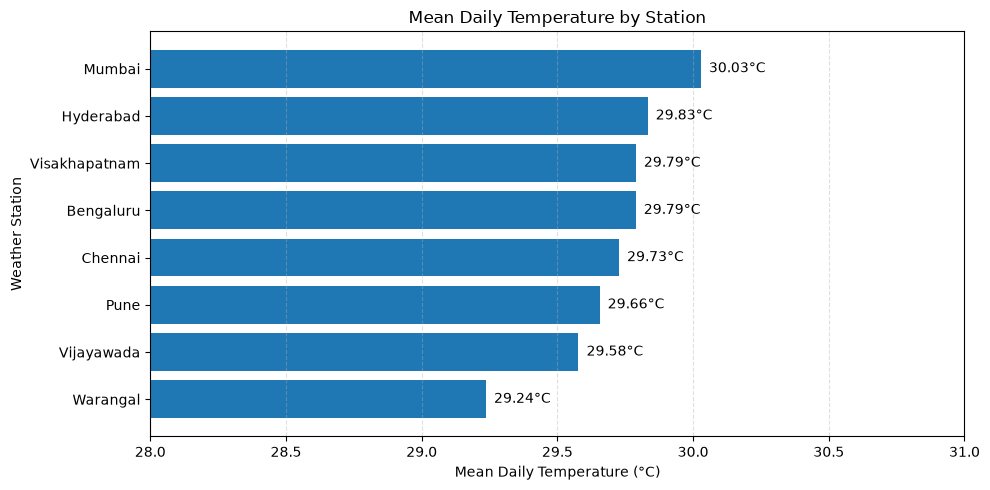

In [96]:
import matplotlib.pyplot as plt

# Collect the small aggregated summary for plotting
temperature_plot_data = (
    station_temperature_summary
    .orderBy("mean_daily_temperature_c")
    .collect()
)

station_names = [row["station_name"] for row in temperature_plot_data]
mean_temperatures = [
    row["mean_daily_temperature_c"] for row in temperature_plot_data
]

plt.figure(figsize=(10, 5))

plt.barh(station_names, mean_temperatures)

plt.title("Mean Daily Temperature by Station")
plt.xlabel("Mean Daily Temperature (°C)")
plt.ylabel("Weather Station")

plt.xlim(28, 31)
plt.grid(axis="x", linestyle="--", alpha=0.4)

for index, value in enumerate(mean_temperatures):
    plt.text(value + 0.03, index, f"{value:.2f}°C", va="center")

plt.tight_layout()
plt.show()

In [97]:
daily_weather.select(
    "station_id",
    "station_name",
    "observation_date",
    "avg_temperature_c"
).orderBy(
    "observation_date",
    "station_id"
).show(20, truncate=False)

+----------+-------------+----------------+------------------+
|station_id|station_name |observation_date|avg_temperature_c |
+----------+-------------+----------------+------------------+
|WX01      |Hyderabad    |2026-06-01      |28.14166666666667 |
|WX02      |Warangal     |2026-06-01      |30.630769230769225|
|WX03      |Vijayawada   |2026-06-01      |30.11333333333334 |
|WX04      |Visakhapatnam|2026-06-01      |27.457142857142856|
|WX05      |Pune         |2026-06-01      |29.24             |
|WX06      |Mumbai       |2026-06-01      |31.04             |
|WX07      |Bengaluru    |2026-06-01      |28.479999999999997|
|WX08      |Chennai      |2026-06-01      |28.89090909090909 |
|WX01      |Hyderabad    |2026-06-02      |29.74444444444445 |
|WX02      |Warangal     |2026-06-02      |26.700000000000003|
|WX03      |Vijayawada   |2026-06-02      |28.461904761904766|
|WX04      |Visakhapatnam|2026-06-02      |29.016666666666666|
|WX05      |Pune         |2026-06-02      |27.730769230

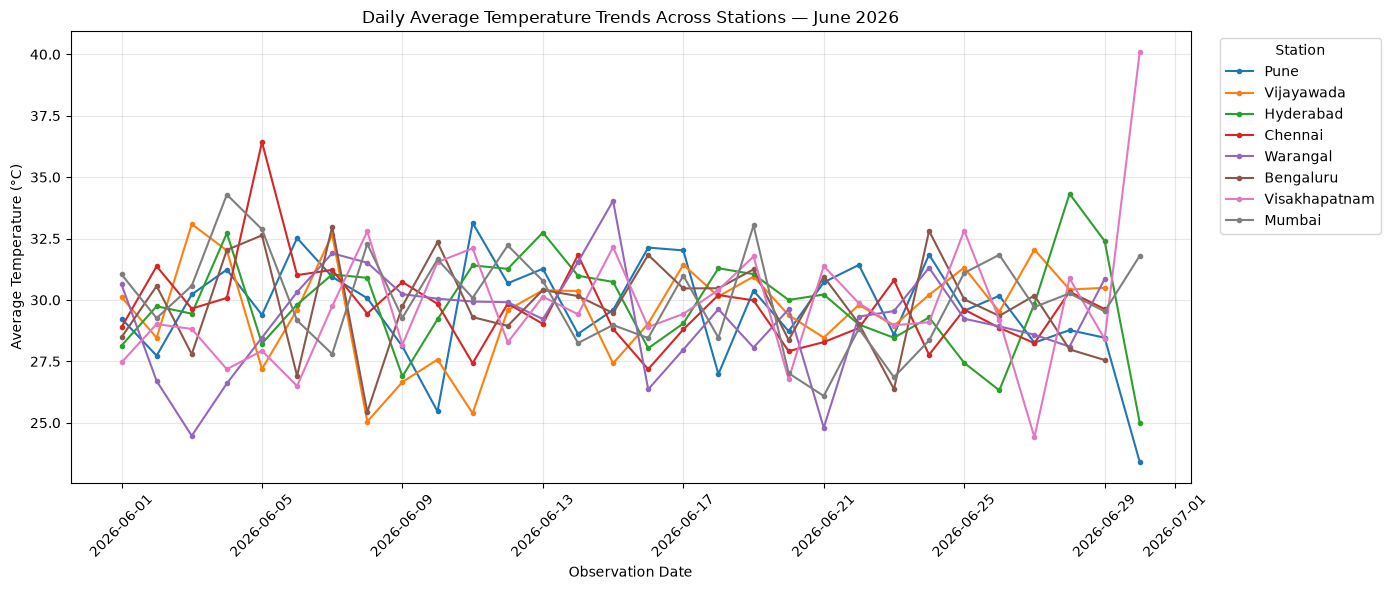

In [98]:
# Collect aggregated daily temperature data
daily_temperature_plot = (
    daily_weather
    .select(
        "station_name",
        "observation_date",
        "avg_temperature_c"
    )
    .orderBy("observation_date")
    .collect()
)

# Prepare data for plotting
station_data = {}

for row in daily_temperature_plot:
    station_data.setdefault(row["station_name"], []).append(
        (row["observation_date"], row["avg_temperature_c"])
    )

plt.figure(figsize=(14, 6))

for station, readings in station_data.items():
    dates = [row[0] for row in readings]
    temperatures = [row[1] for row in readings]

    plt.plot(
        dates,
        temperatures,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=station
    )

plt.title("Daily Average Temperature Trends Across Stations — June 2026")
plt.xlabel("Observation Date")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

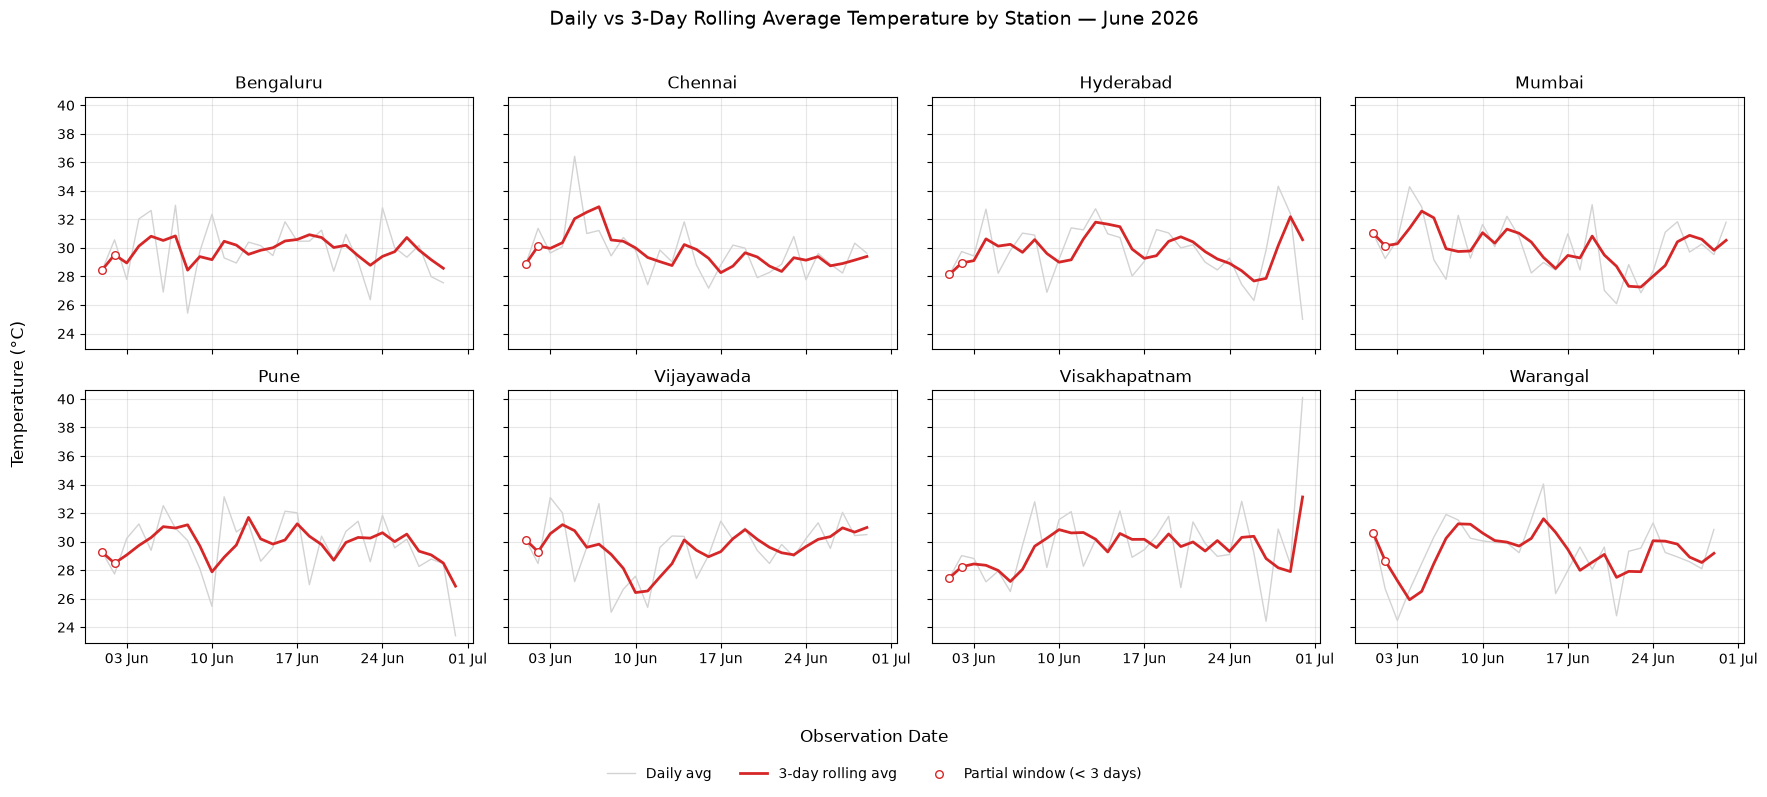

In [99]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

rolling_rows = (
    rolling_3day_temperature
    .orderBy("station_name", "observation_date")
    .collect()
)

# Group rows by station
by_station = {}
for r in rolling_rows:
    by_station.setdefault(r["station_name"], []).append(r)

stations = sorted(by_station)

# Shared y-range so panels are comparable
all_temps = [r[c] for r in rolling_rows
             for c in ("avg_temperature_c", "rolling_3day_avg_temperature_c")
             if r[c] is not None]
y_min, y_max = min(all_temps) - 0.5, max(all_temps) + 0.5

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)

for ax, station in zip(axes.flat, stations):
    rows = by_station[station]
    dates   = [r["observation_date"] for r in rows]
    daily   = [r["avg_temperature_c"] for r in rows]
    rolling = [r["rolling_3day_avg_temperature_c"] for r in rows]

    # Daily average (raw, noisy)
    ax.plot(dates, daily, color="lightgrey", linewidth=1,
            label="Daily avg")

    # 3-day rolling average
    ax.plot(dates, rolling, color="tab:red", linewidth=2,
            label="3-day rolling avg")

    # Mark days where the window held fewer than 3 days of data
    partial = [(r["observation_date"], r["rolling_3day_avg_temperature_c"])
               for r in rows if r["days_in_rolling_window"] < 3]
    if partial:
        ax.scatter([p[0] for p in partial], [p[1] for p in partial],
                   facecolors="white", edgecolors="tab:red", s=30, zorder=3,
                   label="Partial window (< 3 days)")

    ax.set_title(station)
    ax.set_ylim(y_min, y_max)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))

# Shared legend (taken from the first panel)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.0))

fig.supxlabel("Observation Date", y=0.06)
fig.supylabel("Temperature (°C)")
fig.suptitle("Daily vs 3-Day Rolling Average Temperature by Station — June 2026",
             fontsize=14)
plt.tight_layout(rect=[0.02, 0.10, 1, 0.96])
plt.show()